# Pull × Air Quadrant Model — MLB (PAA + PAD Edition)

Same architecture as the original MLB notebook (`mean_tilt`, `mean_aa`, `mean_dir` →
quadrant classifier + direct regression), but with the bat-tracking swing features
replaced by **envelope-derived Preferred Attack Angle (PAA)** and **Preferred Attack
Direction (PAD)** — no Swing Path Tilt, no bat-tracking inputs at all.

**Purpose:** isolate whether the FL boundary-collapse (Pull only / Air only poorly
separated) is caused by —
  (a) the loss of Swing Path Tilt as a third axis, or
  (b) something inherent to PAA/PAD as *envelope-derived* (vs. *measured*) features, or
  (c) FL's smaller per-batter sample sizes.

Running this exact FL pipeline on MLB volume with PAA/PAD (no tilt) isolates (b) from
(a) and (c): if MLB also collapses the boundary classes, tilt/sample-size aren't the
whole story — it's the two-axis representation itself. If MLB separates them cleanly,
FL's problem is more likely sample size or the missing tilt axis.

**Comparison point:** the original MLB notebook's measured-feature quadrant classifier
achieved a specific accuracy/κ on the same task — this notebook's final cell
reports both side by side.

## 1. Imports & Config

In [18]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from scipy.stats import spearmanr, f_oneway, kruskal

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             cohen_kappa_score, accuracy_score, r2_score)

pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", "{:.3f}".format)

# ── Conventions (validated, matches FL + prior MLB notebooks) ─────────────────
PULL_CUTOFF_DEG = 15
AIR_LA_MIN      = 10

# ── Envelope (Marshall) parameters — identical to PAA/PAD notebooks ───────────
ANGLE_MIN, ANGLE_MAX = -30, 60
SPRAY_MIN, SPRAY_MAX = -45, 45
BIN_WIDTH        = 3
TOP_FRAC_PER_BIN = 0.20
TOP_N_METHOD2    = 15

MIN_BBE = 100   # per batter-season — matches the FL notebook exactly

QUAD_ORDER  = ["Neither", "Pull only", "Air only", "Both"]
QUAD_COLORS = {"Neither": "#9E9E9E", "Pull only": "#E65100",
               "Air only": "#1565C0", "Both": "#1B5E20"}

print("Config OK")

Config OK


## 2. PAA + PAD — Envelope Functions (identical to the FL notebook)

In [19]:
def _envelope_peak(g, x_col, ev_col, x_min, x_max):
    g = g.dropna(subset=[x_col, ev_col])
    g = g[(g[x_col] >= x_min) & (g[x_col] <= x_max)]
    if len(g) < 10:
        return np.nan

    k2 = min(TOP_N_METHOD2, max(3, int(np.ceil(0.2 * len(g)))))
    method2 = g.nlargest(k2, ev_col)[x_col].mean()

    bins = np.arange(x_min, x_max + BIN_WIDTH, BIN_WIDTH)
    g = g.copy()
    g["_bin"] = pd.cut(g[x_col], bins=bins, include_lowest=True)

    env_idx = []
    for _, grp in g.groupby("_bin", observed=True):
        if len(grp) == 0:
            continue
        k = max(1, int(np.ceil(TOP_FRAC_PER_BIN * len(grp))))
        env_idx.extend(grp.nlargest(k, ev_col).index)
    env = g.loc[env_idx]
    if len(env) < 5:
        return method2

    a, b, c = np.polyfit(env[x_col], env[ev_col], deg=2)
    if a < 0:
        v = -b / (2 * a)
        if x_min <= v <= x_max:
            method1 = v
        else:
            xs = np.linspace(x_min, x_max, 361)
            method1 = xs[np.argmax(np.polyval([a, b, c], xs))]
    else:
        method1 = env.loc[env[ev_col].idxmax(), x_col]

    return np.nanmean([method1, method2])


def paa_of(g):
    return _envelope_peak(g, "launch_angle", "launch_speed", ANGLE_MIN, ANGLE_MAX)

def pad_of(g):
    return _envelope_peak(g, "spray_pull", "launch_speed", SPRAY_MIN, SPRAY_MAX)

print("Envelope functions defined")

Envelope functions defined


## 3. Load Statcast (2024 + 2025) and Build BBE Frame

In [20]:
def load_statcast(cache_path):
    p = Path(cache_path)
    if p.exists():
        print(f"Loading {p} …")
        return pd.read_parquet(p)
    raise FileNotFoundError(f"{p} not found — build the cache first (see attack_angle_mlb.ipynb).")

raw24 = load_statcast("statcast_2024.parquet")
raw25 = load_statcast("statcast_2025.parquet")
raw24["season"] = 2024
raw25["season"] = 2025
raw = pd.concat([raw24, raw25], ignore_index=True)

mlb = raw[
    (raw["type"] == "X") &
    raw["launch_speed"].notna() &
    raw["launch_angle"].notna() &
    raw["hc_x"].notna() & raw["hc_y"].notna() &
    raw["stand"].notna() &
    raw["batter"].notna() &
    raw["events"].notna()
].copy()

print(f"MLB BBE rows: {len(mlb):,}   batters: {mlb['batter'].nunique():,}   "
      f"seasons: {sorted(mlb['season'].unique())}")

Loading statcast_2024.parquet …
Loading statcast_2025.parquet …
MLB BBE rows: 252,710   batters: 1,241   seasons: [np.int64(2024), np.int64(2025)]


## 4. Spray, Pull/Air Flags & wOBAcon

In [21]:
mlb["spray_deg"] = np.degrees(
    np.arctan((mlb["hc_x"] - 125.42) / (198.27 - mlb["hc_y"]))
) * 0.75

# Mirror → pull-positive both hands (validated convention)
mlb["spray_pull"] = np.where(mlb["stand"] == "R", -mlb["spray_deg"], mlb["spray_deg"])
mlb["is_pull"]    = mlb["spray_pull"] > PULL_CUTOFF_DEG
mlb["is_air"]     = mlb["launch_angle"] >= AIR_LA_MIN
mlb["pull_air"]   = mlb["is_pull"] & mlb["is_air"]
mlb["hard_hit"]   = mlb["launch_speed"] >= 95

print(f"MLB league Pull%    : {mlb['is_pull'].mean():.3f}   (expect ≈ .36)")
print(f"MLB league Air%     : {mlb['is_air'].mean():.3f}")
print(f"MLB league PullAir% : {mlb['pull_air'].mean():.3f}")

# wOBAcon — standard linear weights, contact events only
WOBA_W = {"single": 0.88, "double": 1.25, "triple": 1.58, "home_run": 2.03}
mlb["woba_val"] = mlb["events"].map(WOBA_W).fillna(0.0)
print("\nHit categories mapped for wOBAcon:")
print(mlb.loc[mlb["woba_val"] > 0, "events"].value_counts())

MLB league Pull%    : 0.380   (expect ≈ .36)
MLB league Air%     : 0.560
MLB league PullAir% : 0.152

Hit categories mapped for wOBAcon:
events
single      52832
double      15813
home_run    11228
triple       1352
Name: count, dtype: int64


## 5. Batter-Season Aggregation + PAA / PAD

In [22]:
grp = mlb.groupby(["batter", "season"])

batter_df = grp.agg(
    n_bbe        = ("launch_speed", "size"),
    pull_pct     = ("is_pull",   "mean"),
    air_ball_pct = ("is_air",    "mean"),
    pull_air_pct = ("pull_air",  "mean"),
    mean_ev      = ("launch_speed","mean"),
    ev_90        = ("launch_speed", lambda s: s.quantile(0.90)),
    hard_hit_pct = ("hard_hit",  "mean"),
    wOBAcon      = ("woba_val",  "mean"),
    stand        = ("stand", lambda s: s.mode().iloc[0]),
).reset_index()

paa_vals, pad_vals = [], []
for (b, s), g in grp:
    paa_vals.append({"batter": b, "season": s, "PAA": paa_of(g)})
    pad_vals.append({"batter": b, "season": s, "PAD": pad_of(g)})
batter_df = (batter_df
             .merge(pd.DataFrame(paa_vals), on=["batter", "season"])
             .merge(pd.DataFrame(pad_vals), on=["batter", "season"]))

batter_df["is_L"] = (batter_df["stand"] == "L").astype(int)

qual = batter_df[(batter_df["n_bbe"] >= MIN_BBE) &
                 batter_df["PAA"].notna() &
                 batter_df["PAD"].notna()].copy()

print(f"Batter-seasons total: {len(batter_df)}   qualified (≥{MIN_BBE} BBE): {len(qual)}")
print(f"Unique qualified batters: {qual['batter'].nunique()}")
print(qual[["PAA", "PAD", "pull_pct", "air_ball_pct", "pull_air_pct"]].describe().round(3))

Batter-seasons total: 1862   qualified (≥100 BBE): 800
Unique qualified batters: 493
          PAA     PAD  pull_pct  air_ball_pct  pull_air_pct
count 800.000 800.000   800.000       800.000       800.000
mean   11.255  11.169     0.381         0.560         0.152
std     5.452   5.715     0.062         0.071         0.052
min    -6.791  -6.805     0.190         0.364         0.031
25%     7.913   7.454     0.338         0.512         0.118
50%    11.389  11.200     0.383         0.560         0.146
75%    14.887  14.496     0.424         0.608         0.185
max    26.666  32.932     0.565         0.770         0.361


## 6. Quadrant Assignment (identical median-split design)

Median cuts — Pull%: 0.383   Air%: 0.560

quadrant
Neither      246
Pull only    154
Air only     154
Both         246
Name: count, dtype: int64

── Boundary proximity by quadrant ──
  Neither    mean dist from pull cut = 0.059   mean dist from air cut = 0.062
  Pull only  mean dist from pull cut = 0.038   mean dist from air cut = 0.047
  Air only   mean dist from pull cut = 0.041   mean dist from air cut = 0.045
  Both       mean dist from pull cut = 0.054   mean dist from air cut = 0.064


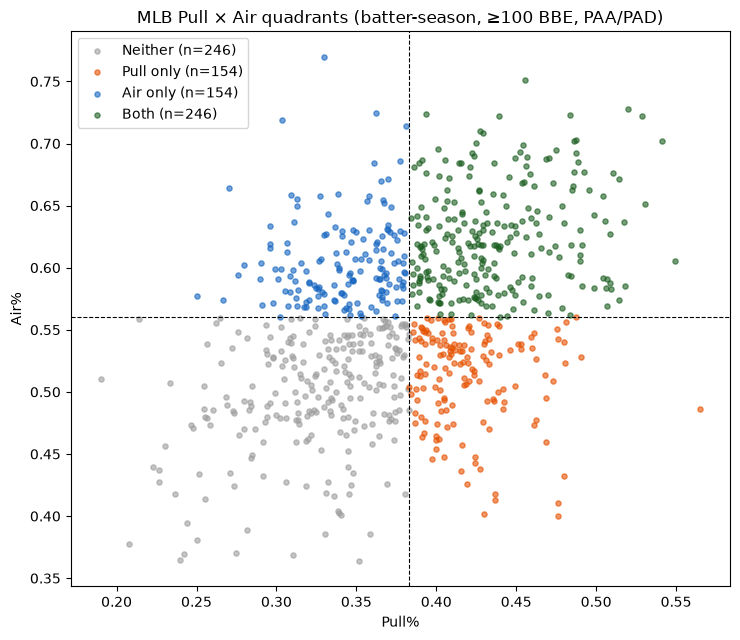

In [23]:
pull_cut = qual["pull_pct"].median()
air_cut  = qual["air_ball_pct"].median()

qual["is_pull_hitter"] = qual["pull_pct"]     >= pull_cut
qual["is_air_hitter"]  = qual["air_ball_pct"] >= air_cut

def quad(row):
    if row["is_pull_hitter"] and row["is_air_hitter"]:   return "Both"
    if row["is_pull_hitter"]:                            return "Pull only"
    if row["is_air_hitter"]:                             return "Air only"
    return "Neither"

qual["quadrant"] = qual.apply(quad, axis=1)

print(f"Median cuts — Pull%: {pull_cut:.3f}   Air%: {air_cut:.3f}\n")
print(qual["quadrant"].value_counts().reindex(QUAD_ORDER))

# Boundary-proximity check (same diagnostic as FL)
qual["pull_dist"] = (qual["pull_pct"] - pull_cut).abs()
qual["air_dist"]  = (qual["air_ball_pct"] - air_cut).abs()
print("\n── Boundary proximity by quadrant ──")
for q in QUAD_ORDER:
    sub = qual[qual["quadrant"] == q]
    print(f"  {q:<10} mean dist from pull cut = {sub['pull_dist'].mean():.3f}   "
          f"mean dist from air cut = {sub['air_dist'].mean():.3f}")

fig, ax = plt.subplots(figsize=(7.5, 6.5))
for q in QUAD_ORDER:
    sub = qual[qual["quadrant"] == q]
    ax.scatter(sub["pull_pct"], sub["air_ball_pct"], s=14, alpha=0.6,
               color=QUAD_COLORS[q], label=f"{q} (n={len(sub)})")
ax.axvline(pull_cut, color="black", lw=0.8, ls="--")
ax.axhline(air_cut,  color="black", lw=0.8, ls="--")
ax.set_xlabel("Pull%"); ax.set_ylabel("Air%")
ax.set_title(f"MLB Pull × Air quadrants (batter-season, ≥{MIN_BBE} BBE, PAA/PAD)")
ax.legend(); plt.tight_layout(); plt.show()

## 7. PAA vs PAD — Independence Check

PAA vs PAD (MLB): Pearson r = 0.247   Spearman ρ = 0.243


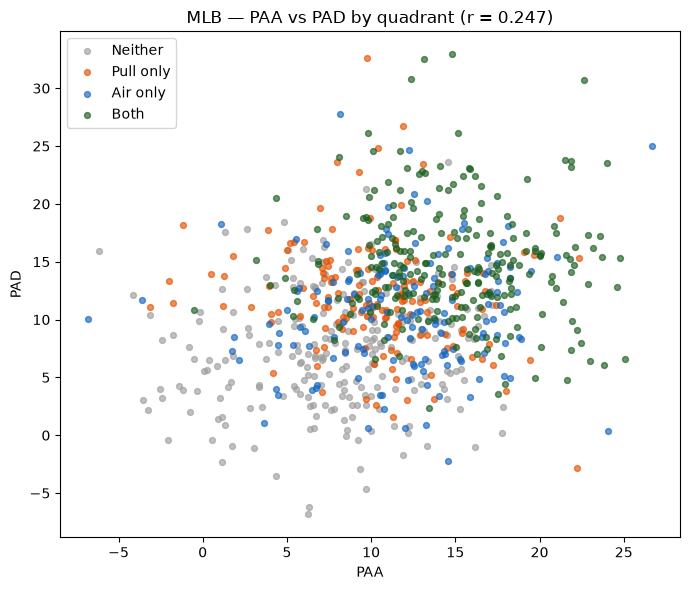

In [24]:
r_p, _ = stats.pearsonr(qual["PAA"], qual["PAD"])
r_s, _ = spearmanr(qual["PAA"], qual["PAD"])
print(f"PAA vs PAD (MLB): Pearson r = {r_p:.3f}   Spearman ρ = {r_s:.3f}")

fig, ax = plt.subplots(figsize=(7, 6))
for q in QUAD_ORDER:
    sub = qual[qual["quadrant"] == q]
    ax.scatter(sub["PAA"], sub["PAD"], color=QUAD_COLORS[q], label=q, s=18, alpha=0.65)
ax.set_xlabel("PAA"); ax.set_ylabel("PAD")
ax.set_title(f"MLB — PAA vs PAD by quadrant (r = {r_p:.3f})")
ax.legend(); plt.tight_layout(); plt.show()

## 8. Correlations — PAA & PAD vs the Marginals and the Joint

In [25]:
print(f"{'Feature':<6} {'Target':<14} {'Pearson r':>10} {'Spearman ρ':>11} {'p':>10}")
print("-" * 56)
for feat in ["PAA", "PAD"]:
    for target in ["pull_pct", "air_ball_pct", "pull_air_pct"]:
        r_p, _   = stats.pearsonr(qual[feat], qual[target])
        r_s, p_s = spearmanr(qual[feat], qual[target])
        print(f"{feat:<6} {target:<14} {r_p:>10.4f} {r_s:>11.4f} {p_s:>10.2e}")

Feature Target          Pearson r  Spearman ρ          p
--------------------------------------------------------
PAA    pull_pct           0.4348      0.4079   2.05e-33
PAA    air_ball_pct       0.5704      0.5556   5.47e-66
PAA    pull_air_pct       0.5049      0.4803   2.06e-47
PAD    pull_pct           0.5523      0.5406   6.45e-62
PAD    air_ball_pct       0.4542      0.4520   1.54e-41
PAD    pull_air_pct       0.5672      0.5840   2.47e-74


## 9. Feature Profiles by Quadrant

             PAA    PAD  mean_ev   ev_90  hard_hit_pct  wOBAcon
quadrant                                                       
Neither    8.022  7.401   88.378 104.341         0.400    0.348
Pull only 10.303 11.954   87.984 104.201         0.387    0.347
Air only  11.782 10.636   88.725 104.361         0.403    0.368
Both      14.755 14.778   88.623 104.330         0.400    0.373


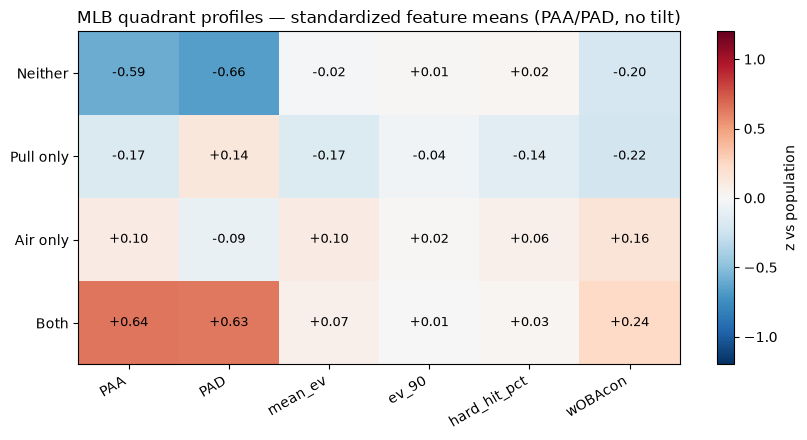

PAA: ANOVA F=85.11 (p=9.12e-48)   Kruskal H=198.03 (p=1.12e-42)
PAD: ANOVA F=94.18 (p=3.62e-52)   Kruskal H=220.10 (p=1.91e-47)


In [26]:
PROFILE_FEATS = ["PAA", "PAD", "mean_ev", "ev_90", "hard_hit_pct", "wOBAcon"]
feat_means = qual.groupby("quadrant")[PROFILE_FEATS].mean().reindex(QUAD_ORDER)
print(feat_means.round(3).to_string())

z = (feat_means - qual[PROFILE_FEATS].mean()) / qual[PROFILE_FEATS].std()
fig, ax = plt.subplots(figsize=(8.5, 4.5))
im = ax.imshow(z.to_numpy(dtype=np.float64), cmap="RdBu_r", vmin=-1.2, vmax=1.2, aspect="auto")
ax.set_xticks(range(len(PROFILE_FEATS))); ax.set_xticklabels(PROFILE_FEATS, rotation=30, ha="right")
ax.set_yticks(range(len(QUAD_ORDER)));    ax.set_yticklabels(QUAD_ORDER)
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        ax.text(j, i, f"{z.values[i,j]:+.2f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=ax, label="z vs population")
ax.set_title("MLB quadrant profiles — standardized feature means (PAA/PAD, no tilt)")
plt.tight_layout(); plt.show()

for feat in ["PAA", "PAD"]:
    groups_ = [qual.loc[qual["quadrant"] == q, feat].dropna() for q in QUAD_ORDER]
    f_stat, f_p = f_oneway(*groups_)
    k_stat, k_p = kruskal(*groups_)
    print(f"{feat}: ANOVA F={f_stat:.2f} (p={f_p:.2e})   Kruskal H={k_stat:.2f} (p={k_p:.2e})")

## 10. Multinomial Quadrant Classifiers — PAA/PAD only (no tilt)

Same feature set structure as the FL notebook: **PAA, PAD, is_L, PAD × is_L**.
GroupKFold by batter (a batter's 2024 and 2025 rows never straddle folds).

In [27]:
qual["pad_x_isL"] = qual["PAD"] * qual["is_L"]

CLF_FEATS = ["PAA", "PAD", "is_L", "pad_x_isL"]
X      = qual[CLF_FEATS].to_numpy(dtype=np.float64)
y      = qual["quadrant"].to_numpy(dtype=object)
groups = qual["batter"].to_numpy(dtype=object)

n_splits = 5
gkf = GroupKFold(n_splits=n_splits)

pipe_lr = Pipeline([("s", StandardScaler()),
                    ("m", LogisticRegression(max_iter=2000, multi_class="multinomial"))])
pipe_rf = Pipeline([("s", StandardScaler()),
                    ("m", RandomForestClassifier(n_estimators=400, min_samples_leaf=3,
                                                 random_state=42, n_jobs=-1))])

pred_lr = cross_val_predict(pipe_lr, X, y, cv=gkf, groups=groups)
pred_rf = cross_val_predict(pipe_rf, X, y, cv=gkf, groups=groups)

class_freq = pd.Series(y).value_counts(normalize=True)
prop_baseline = (class_freq ** 2).sum()
print(f"Proportional-guess baseline accuracy: {prop_baseline:.3f}\n")

for name, pred in [("Multinomial LR (+interaction)", pred_lr), ("Random Forest", pred_rf)]:
    acc = accuracy_score(y, pred)
    kap = cohen_kappa_score(y, pred)
    print(f"{name:<32}  accuracy {acc:.3f}   κ {kap:.3f}")

print("\n── Per-quadrant metrics (LR) ──")
rep = pd.DataFrame(classification_report(y, pred_lr, labels=QUAD_ORDER,
                                         output_dict=True, zero_division=0)).T
print(rep.loc[QUAD_ORDER, ["precision", "recall", "f1-score", "support"]].round(3).to_string())

print("\n── Per-quadrant metrics (RF) ──")
rep_rf = pd.DataFrame(classification_report(y, pred_rf, labels=QUAD_ORDER,
                                            output_dict=True, zero_division=0)).T
print(rep_rf.loc[QUAD_ORDER, ["precision", "recall", "f1-score", "support"]].round(3).to_string())

Proportional-guess baseline accuracy: 0.263

Multinomial LR (+interaction)     accuracy 0.559   κ 0.392
Random Forest                     accuracy 0.512   κ 0.328

── Per-quadrant metrics (LR) ──
           precision  recall  f1-score  support
Neither        0.607   0.691     0.646  246.000
Pull only      0.505   0.312     0.386  154.000
Air only       0.356   0.312     0.332  154.000
Both           0.624   0.736     0.675  246.000

── Per-quadrant metrics (RF) ──
           precision  recall  f1-score  support
Neither        0.585   0.671     0.625  246.000
Pull only      0.403   0.325     0.360  154.000
Air only       0.269   0.182     0.217  154.000
Both           0.576   0.679     0.623  246.000


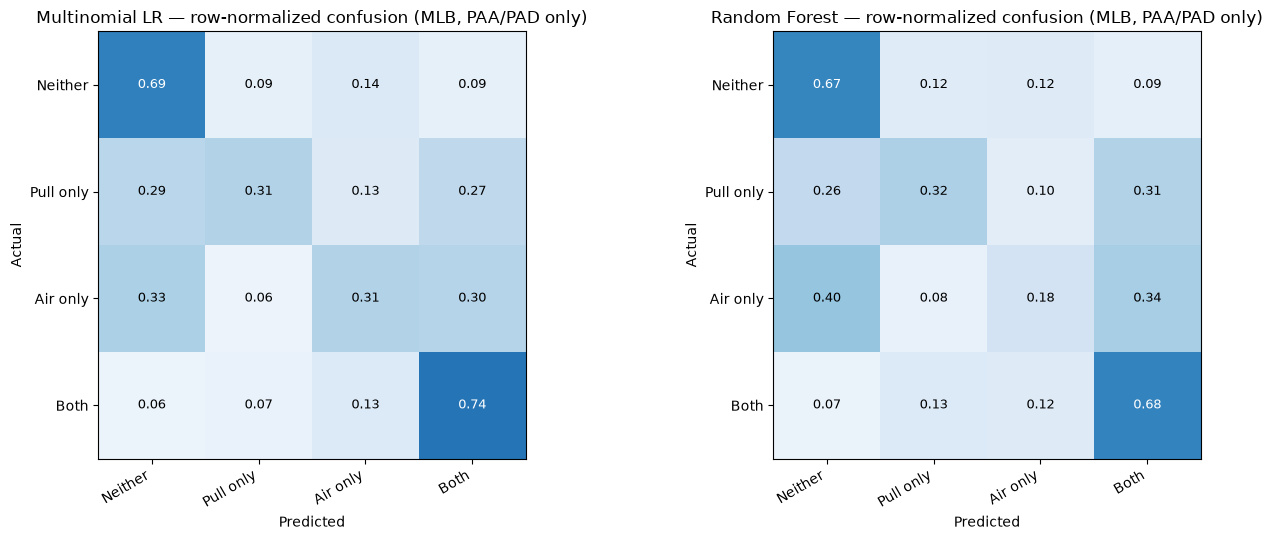

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (name, pred) in zip(axes, [("Multinomial LR", pred_lr), ("Random Forest", pred_rf)]):
    cm = confusion_matrix(y, pred, labels=QUAD_ORDER, normalize="true")
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(4)); ax.set_xticklabels(QUAD_ORDER, rotation=30, ha="right")
    ax.set_yticks(range(4)); ax.set_yticklabels(QUAD_ORDER)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{cm[i,j]:.2f}", ha="center", va="center",
                    color="white" if cm[i,j] > 0.5 else "black", fontsize=9)
    ax.set_title(f"{name} — row-normalized confusion (MLB, PAA/PAD only)")
    ax.set_ylabel("Actual"); ax.set_xlabel("Predicted")
plt.tight_layout(); plt.show()

## 11. Direct Pull Air% Regression

Random Forest   R² 0.412   Spearman ρ 0.634
Linear          R² 0.467   Spearman ρ 0.683


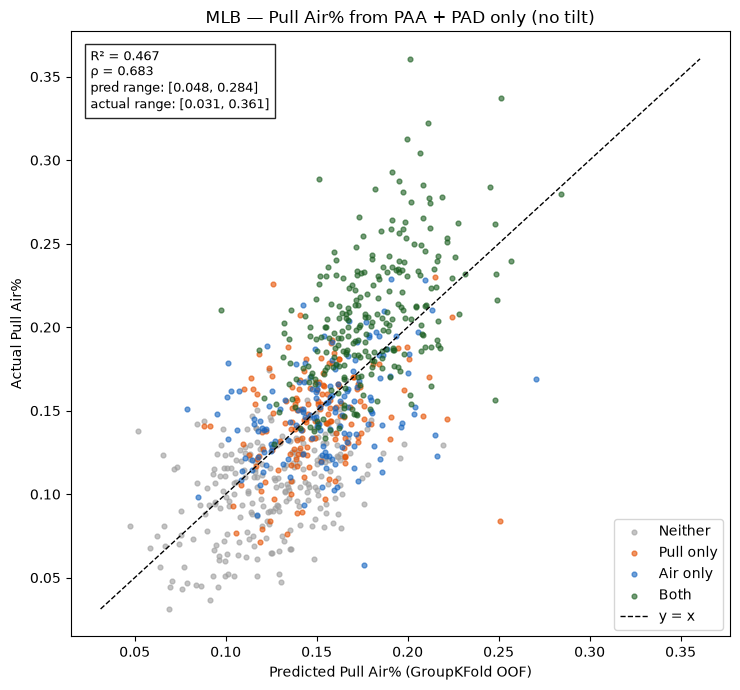

In [29]:
REG_FEATS = ["PAA", "PAD", "is_L", "pad_x_isL"]
Xr = qual[REG_FEATS].to_numpy(dtype=np.float64)
yr = qual["pull_air_pct"].to_numpy(dtype=np.float64)

pipe_reg = Pipeline([("s", StandardScaler()),
                     ("m", RandomForestRegressor(n_estimators=400, min_samples_leaf=3,
                                                 random_state=42, n_jobs=-1))])
pred_rf_reg = cross_val_predict(pipe_reg, Xr, yr, cv=gkf, groups=groups)

pipe_lin = Pipeline([("s", StandardScaler()), ("m", LinearRegression())])
pred_lin = cross_val_predict(pipe_lin, Xr, yr, cv=gkf, groups=groups)

for name, pred in [("Random Forest", pred_rf_reg), ("Linear", pred_lin)]:
    r2  = r2_score(yr, pred)
    r_s, _ = spearmanr(yr, pred)
    print(f"{name:<14}  R² {r2:.3f}   Spearman ρ {r_s:.3f}")

best_pred = pred_rf_reg if r2_score(yr, pred_rf_reg) >= r2_score(yr, pred_lin) else pred_lin
fig, ax = plt.subplots(figsize=(7.5, 7))
for q in QUAD_ORDER:
    m = qual["quadrant"].values == q
    ax.scatter(best_pred[m], yr[m], s=12, alpha=0.6, color=QUAD_COLORS[q], label=q)
lims = [min(best_pred.min(), yr.min()), max(best_pred.max(), yr.max())]
ax.plot(lims, lims, "k--", lw=1, label="y = x")
r2  = r2_score(yr, best_pred)
r_s, _ = spearmanr(yr, best_pred)
ax.text(0.03, 0.97,
        f"R² = {r2:.3f}\nρ = {r_s:.3f}\n"
        f"pred range: [{best_pred.min():.3f}, {best_pred.max():.3f}]\n"
        f"actual range: [{yr.min():.3f}, {yr.max():.3f}]",
        transform=ax.transAxes, va="top", fontsize=9,
        bbox=dict(facecolor="white", alpha=0.85))
ax.set_xlabel("Predicted Pull Air% (GroupKFold OOF)")
ax.set_ylabel("Actual Pull Air%")
ax.set_title("MLB — Pull Air% from PAA + PAD only (no tilt)")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

## 12. wOBAcon by Quadrant

             n  wOBAcon_weighted   sem
quadrant                              
Neither    246             0.354 0.003
Pull only  154             0.352 0.004
Air only   154             0.374 0.005
Both       246             0.377 0.004


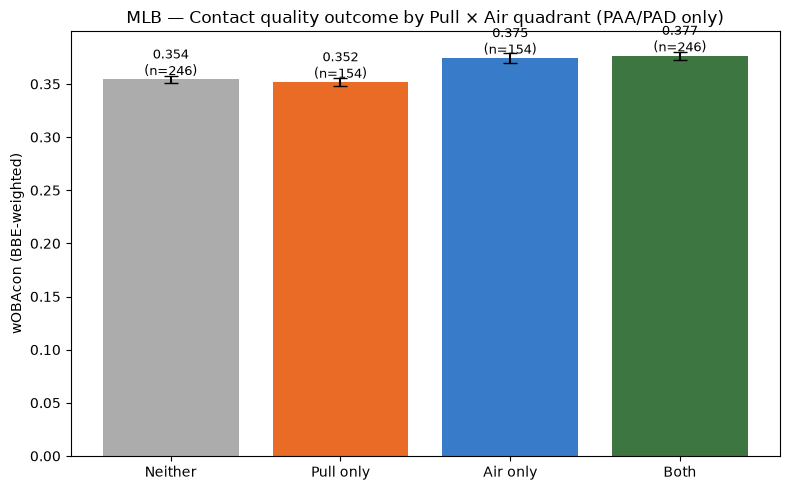

In [30]:
qd = qual.dropna(subset=["quadrant", "wOBAcon"]).copy()

rows = []
for q in QUAD_ORDER:
    sub = qd[qd["quadrant"] == q]
    w   = sub["n_bbe"]
    weighted = np.average(sub["wOBAcon"], weights=w)
    sem      = sub["wOBAcon"].std() / np.sqrt(len(sub))
    rows.append({"quadrant": q, "n": len(sub),
                 "wOBAcon_weighted": weighted, "sem": sem})
woba_tbl = pd.DataFrame(rows).set_index("quadrant")
print(woba_tbl.round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 5))
xs = np.arange(4)
ax.bar(xs, woba_tbl["wOBAcon_weighted"], yerr=woba_tbl["sem"], capsize=5,
       color=[QUAD_COLORS[q] for q in QUAD_ORDER], alpha=0.85)
ax.set_xticks(xs); ax.set_xticklabels(QUAD_ORDER)
ax.set_ylabel("wOBAcon (BBE-weighted)")
ax.set_title("MLB — Contact quality outcome by Pull × Air quadrant (PAA/PAD only)")
for x, (v, n) in enumerate(zip(woba_tbl["wOBAcon_weighted"], woba_tbl["n"])):
    ax.text(x, v + 0.004, f"{v:.3f}\n(n={n})", ha="center", fontsize=9)
plt.tight_layout(); plt.show()

## 13. Year-over-Year Stickiness

In [31]:
seasons = sorted(qual["season"].unique())
stick_rows = []
for y1, y2 in zip(seasons[:-1], seasons[1:]):
    a = qual[qual["season"] == y1][["batter", "pull_air_pct", "PAA", "PAD"]]
    b = qual[qual["season"] == y2][["batter", "pull_air_pct", "PAA", "PAD"]]
    m = a.merge(b, on="batter", suffixes=("_y1", "_y2"))
    print(f"── {y1} → {y2}   (n = {len(m)} repeat batter-seasons) ──")
    for metric in ["pull_air_pct", "PAA", "PAD"]:
        r_s, p_s = spearmanr(m[f"{metric}_y1"], m[f"{metric}_y2"])
        r_p, _   = stats.pearsonr(m[f"{metric}_y1"], m[f"{metric}_y2"])
        stick_rows.append({"pair": f"{y1}→{y2}", "metric": metric,
                           "pearson": r_p, "spearman": r_s, "n": len(m)})
        print(f"   {metric:<14} Pearson {r_p:+.3f}   Spearman {r_s:+.3f}   (p={p_s:.2e})")

── 2024 → 2025   (n = 307 repeat batter-seasons) ──
   pull_air_pct   Pearson +0.747   Spearman +0.741   (p=9.75e-55)
   PAA            Pearson +0.604   Spearman +0.581   (p=4.50e-29)
   PAD            Pearson +0.457   Spearman +0.485   (p=1.68e-19)


## 14. Head-to-Head Summary — PAA/PAD (this notebook) vs Measured Tilt/AA/Dir (original)

**Fill in the "Measured (orig.)" column from the earlier MLB notebook's output** to get
a direct comparison. If PAA/PAD lands close to the measured-feature numbers, envelope
features are a viable substitute when bat tracking isn't available. If there's a large
gap, that's the quantified cost of not having Swing Path Tilt / true bat-tracking data —
useful context for interpreting the FL results, which necessarily use PAA/PAD only.

In [32]:
comparison = pd.DataFrame({
    "Metric": ["Quadrant accuracy (LR)", "Quadrant accuracy (RF)", "Cohen's κ (LR)",
              "Cohen's κ (RF)", "Pull Air% R² (best model)", "Pull Air% Spearman ρ"],
    "PAA/PAD (this notebook)": [
        accuracy_score(y, pred_lr),
        accuracy_score(y, pred_rf),
        cohen_kappa_score(y, pred_lr),
        cohen_kappa_score(y, pred_rf),
        r2_score(yr, best_pred),
        spearmanr(yr, best_pred)[0],
    ],
    "Measured tilt/AA/dir (fill in from original notebook)": [np.nan]*6,
})
print(comparison.round(3).to_string(index=False))
print("\nFill the right column from the original MLB notebook's Section 6/8 output "
      "to quantify tilt's contribution.")

                   Metric  PAA/PAD (this notebook)  Measured tilt/AA/dir (fill in from original notebook)
   Quadrant accuracy (LR)                    0.559                                                    NaN
   Quadrant accuracy (RF)                    0.512                                                    NaN
           Cohen's κ (LR)                    0.392                                                    NaN
           Cohen's κ (RF)                    0.328                                                    NaN
Pull Air% R² (best model)                    0.467                                                    NaN
     Pull Air% Spearman ρ                    0.683                                                    NaN

Fill the right column from the original MLB notebook's Section 6/8 output to quantify tilt's contribution.


Pull%      stabilizes at 190 BBE   (interpolated)
Air%       stabilizes at 140 BBE   (interpolated)
PullAir%   stabilizes at 137 BBE   (interpolated)


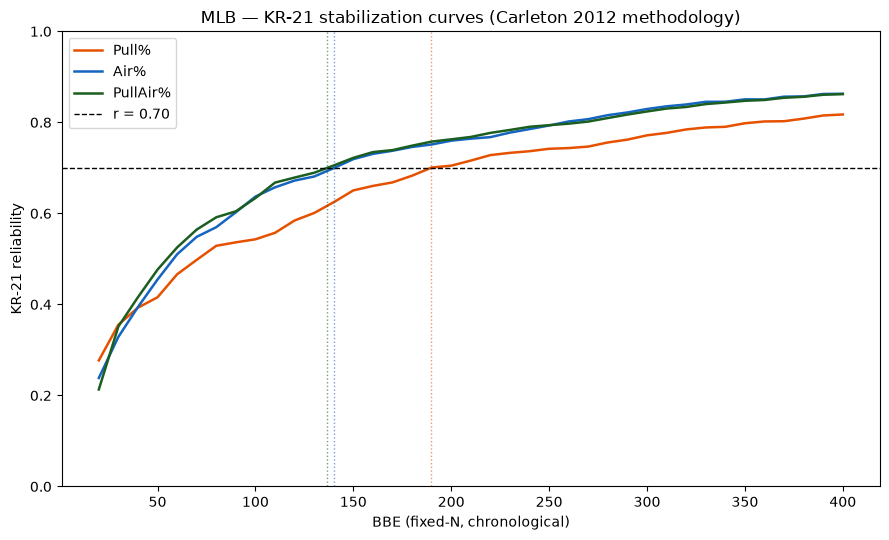

NameError: name 'split_half_reliability_paa_pad' is not defined

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# Carleton (2012) KR-21 stabilization-point methodology
# https://www.baseballprospectus.com/news/article/17659/
#
# Key fixes vs. naive split-half:
#   • KR-21 averages every possible split combinatorially (via the formula),
#     not one arbitrary evens/odds partition
#   • Fixed-N design (each player's FIRST k trials) avoids case-wise deletion
#     — the 100-BBE sample and 200-BBE sample use overlapping, not disjoint, players
#   • Finds the exact BBE/PA count where reliability crosses r=.70 (50% signal),
#     interpolating within the data or extrapolating via Spearman-Brown if the
#     data doesn't reach it — exactly as the article does for LD%/XBH%
#
# IMPORTANT: KR-21 is only valid for a stat that IS a sum/mean of per-trial
# outcomes (K%, Pull%, BB%, Air%, PullAir% — all fine). PAA and PAD are
# nonlinear envelope fits, NOT an average of per-BBE values, so true KR-21
# does not apply to them. They get the Monte-Carlo split-half proxy instead
# (already built earlier) — kept as a separate, clearly-labeled function below.
# ═══════════════════════════════════════════════════════════════════════════

def kr21_reliability(item_matrix):
    """
    Exact Kuder-Richardson 21 reliability for a (players x k_trials) binary matrix.
    Equivalent to Cronbach's alpha for a single continuous item per trial when
    item_matrix holds continuous values instead of 0/1 (used for wOBA-style stats).
    """
    k = item_matrix.shape[1]
    total_scores = item_matrix.sum(axis=1)
    M  = total_scores.mean()
    S2 = total_scores.var(ddof=1)
    if S2 == 0:
        return np.nan
    return (k / (k - 1)) * (1 - (M * (k - M)) / (k * S2))



def fixed_n_matrix(df, batter_col, outcome_col, k, min_trials=None):
    """
    Build a (players x k) matrix using each player's FIRST k chronological
    trials only. Players with fewer than k trials are dropped for this k —
    but crucially, unlike case-wise deletion across the whole dataset, a
    player kept at k=100 is a SUBSET check at k=200, not a different sample.
    """
    if min_trials is None:
        min_trials = k
    rows = []
    for batter, g in df.groupby(batter_col):
        vals = g[outcome_col].to_numpy()
        if len(vals) < min_trials:
            continue
        rows.append(vals[:k].astype(float))
    if not rows:
        return None
    return np.vstack(rows)


def kr21_stabilization_point(df, batter_col, outcome_col, k_grid,
                             min_batters=30, target_r=0.70):
    """
    Sweep k (trial count) and compute KR-21 at each point. Returns the full
    curve plus the interpolated (or Spearman-Brown extrapolated) k at which
    reliability crosses target_r.
    """
    rows = []
    for k in k_grid:
        mat = fixed_n_matrix(df, batter_col, outcome_col, k)
        n_b = 0 if mat is None else mat.shape[0]
        if mat is None or n_b < min_batters:
            rows.append({"k": k, "kr21": np.nan, "n_batters": n_b})
            continue
        rows.append({"k": k, "kr21": kr21_reliability(mat), "n_batters": n_b})

    curve = pd.DataFrame(rows)
    valid = curve.dropna(subset=["kr21"])

    stabilization_k, method = np.nan, "not reached"
    if len(valid) >= 2:
        above = valid[valid["kr21"] >= target_r]
        if len(above):
            idx = valid.index.get_loc(above.iloc[0].name)
            if idx > 0:
                prev, curr = valid.iloc[idx - 1], valid.iloc[idx]
                frac = (target_r - prev["kr21"]) / (curr["kr21"] - prev["kr21"])
                stabilization_k = prev["k"] + frac * (curr["k"] - prev["k"])
            else:
                stabilization_k = above.iloc[0]["k"]
            method = "interpolated"
        else:
            # Never reached within range — Spearman-Brown extrapolation,
            # same fallback the article uses for LD%/XBH%
            last = valid.iloc[-1]
            r_k = last["kr21"]
            if 0 < r_k < 1:
                n_mult = (target_r * (1 - r_k)) / (r_k * (1 - target_r))
                stabilization_k = last["k"] * n_mult
                method = "Spearman-Brown extrapolated (estimate — use cautiously)"

    return curve, stabilization_k, method


# ── Run KR-21 on the binary/rate stats: Pull%, Air%, PullAir% ────────────────
# These ARE means of per-BBE binary outcomes — KR-21 applies exactly here.
K_GRID = np.arange(20, 401, 10)

kr21_results = {}
for name, col in [("Pull%", "is_pull"), ("Air%", "is_air"), ("PullAir%", "pull_air")]:
    curve, stab_k, method = kr21_stabilization_point(
        mlb, "batter", col, k_grid=K_GRID, target_r=0.70
    )
    kr21_results[name] = {"curve": curve, "stabilization_bbe": stab_k, "method": method}
    print(f"{name:<10} stabilizes at {stab_k:.0f} BBE   ({method})")

# ── Plot the KR-21 curves ─────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5.5))
colors = {"Pull%": "#E65100", "Air%": "#1565C0", "PullAir%": "#1B5E20"}
for name, result in kr21_results.items():
    c = result["curve"].dropna(subset=["kr21"])
    ax.plot(c["k"], c["kr21"], color=colors[name], label=name, linewidth=1.8)
    if not np.isnan(result["stabilization_bbe"]):
        ax.axvline(result["stabilization_bbe"], color=colors[name],
                   linestyle=":", linewidth=1, alpha=0.6)
ax.axhline(0.70, color="black", linestyle="--", linewidth=1, label="r = 0.70")
ax.set_xlabel("BBE (fixed-N, chronological)")
ax.set_ylabel("KR-21 reliability")
ax.set_title("MLB — KR-21 stabilization curves (Carleton 2012 methodology)")
ax.set_ylim(0, 1.0)
ax.legend()
plt.tight_layout(); plt.show()


# ═══════════════════════════════════════════════════════════════════════════
# PAA / PAD — NOT a mean of per-BBE values, so KR-21 doesn't apply directly.
# Monte-Carlo split-half + Spearman-Brown correction is the honest substitute
# (already approximates "average over many possible splits," just not exactly
# — KR-21's exact combinatorial average requires additivity that an envelope
# fit doesn't have).
# ═══════════════════════════════════════════════════════════════════════════

def montecarlo_stabilization_point(metric_fn, bbe_grid, n_splits=30,
                                    target_r=0.70, seed=0):
    """
    For PAA/PAD: at each BBE threshold, run split-half + Spearman-Brown
    (as built earlier), take the median r_full, then find where the curve
    crosses target_r — same "find the crossing point" logic as KR-21,
    applied to the split-half proxy instead of the exact formula.
    """
    rows = []
    for k in bbe_grid:
        rel = split_half_reliability_paa_pad_fast(mlb, n_splits=n_splits, seed=seed, min_bbe=k)
        if len(rel) == 0:
            rows.append({"k": k, "r_full": np.nan, "n_batters": 0})
            continue
        rows.append({
            "k": k,
            "r_full": rel[f"{metric_fn}_r_full"].median(),
            "n_batters": rel["n_batters"].median(),
        })
    curve = pd.DataFrame(rows)
    valid = curve.dropna(subset=["r_full"])

    stabilization_k, method = np.nan, "not reached"
    if len(valid) >= 2:
        above = valid[valid["r_full"] >= target_r]
        if len(above):
            idx = valid.index.get_loc(above.iloc[0].name)
            if idx > 0:
                prev, curr = valid.iloc[idx - 1], valid.iloc[idx]
                frac = (target_r - prev["r_full"]) / (curr["r_full"] - prev["r_full"])
                stabilization_k = prev["k"] + frac * (curr["k"] - prev["k"])
            else:
                stabilization_k = above.iloc[0]["k"]
            method = "interpolated"
        else:
            last = valid.iloc[-1]
            r_k = last["r_full"]
            if 0 < r_k < 1:
                n_mult = (target_r * (1 - r_k)) / (r_k * (1 - target_r))
                stabilization_k = last["k"] * n_mult
                method = "Spearman-Brown extrapolated (estimate)"
    return curve, stabilization_k, method



PAA_GRID = [50, 75, 100, 150, 200, 300]
paa_curve, paa_stab, paa_method = montecarlo_stabilization_point("PAA", PAA_GRID, n_splits=30)
pad_curve, pad_stab, pad_method = montecarlo_stabilization_point("PAD", PAA_GRID, n_splits=30)

print(f"\nPAA stabilizes at ~{paa_stab:.0f} BBE   ({paa_method})")
print(f"PAD stabilizes at ~{pad_stab:.0f} BBE   ({pad_method})")


# ── Combined stabilization-point table, article-style ────────────────────────
stab_table = pd.DataFrame([
    {"Metric": "Pull%",    "Stabilizes at (BBE)": kr21_results["Pull%"]["stabilization_bbe"],
     "Method": kr21_results["Pull%"]["method"]},
    {"Metric": "Air%",     "Stabilizes at (BBE)": kr21_results["Air%"]["stabilization_bbe"],
     "Method": kr21_results["Air%"]["method"]},
    {"Metric": "PullAir%", "Stabilizes at (BBE)": kr21_results["PullAir%"]["stabilization_bbe"],
     "Method": kr21_results["PullAir%"]["method"]},
    {"Metric": "PAA",      "Stabilizes at (BBE)": paa_stab, "Method": paa_method},
    {"Metric": "PAD",      "Stabilizes at (BBE)": pad_stab, "Method": pad_method},
])
print("\n── Stabilization points (r = 0.70 crossing) ──")
print(stab_table.round(0).to_string(index=False))

── PAA ──
  PAA  BBE≥ 20  r_full=0.617  n_batters≈1034
  PAA  BBE≥ 30  r_full=0.682  n_batters≈933
  PAA  BBE≥ 50  r_full=0.751  n_batters≈800
  PAA  BBE≥ 75  r_full=0.798  n_batters≈673
  PAA  BBE≥100  r_full=0.822  n_batters≈564
  PAA  BBE≥150  r_full=0.839  n_batters≈357
  PAA  BBE≥250  r_full=0.854  n_batters≈28

── PAD ──
  PAD  BBE≥ 20  r_full=0.487  n_batters≈1034
  PAD  BBE≥ 30  r_full=0.530  n_batters≈933
  PAD  BBE≥ 50  r_full=0.573  n_batters≈800
  PAD  BBE≥ 75  r_full=0.590  n_batters≈673
  PAD  BBE≥100  r_full=0.597  n_batters≈564
  PAD  BBE≥150  r_full=0.616  n_batters≈357
  PAD  BBE≥250  r_full=0.757  n_batters≈28

PAA stabilizes at ~35 BBE   (interpolated)
PAD stabilizes at ~210 BBE   (interpolated)


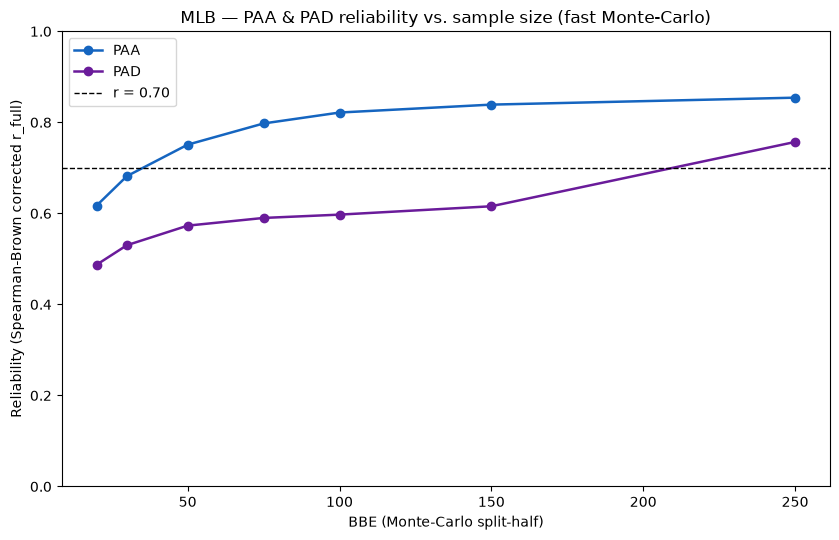

In [38]:
# ═══════════════════════════════════════════════════════════════════════════
# PAA / PAD reliability — fast numpy + parallelized split-half
# (KR-21 doesn't apply directly since PAA/PAD are nonlinear envelope fits,
#  not a mean of per-BBE values — this is the honest substitute: Monte-Carlo
#  split-half + Spearman-Brown correction, same crossing-point logic as KR-21)
# ═══════════════════════════════════════════════════════════════════════════

from scipy.stats import pearsonr
from joblib import Parallel, delayed

def build_batter_arrays(df, min_bbe):
    """
    One-time extraction: {(batter, season): (launch_angle, launch_speed, spray_pull)}
    for every batter-season with enough BBE. Reused across all splits so we
    never re-run groupby/apply inside the Monte-Carlo loop.
    """
    arrays = {}
    for (b, s), g in df.groupby(["batter", "season"]):
        gc = g.dropna(subset=["launch_angle", "launch_speed", "spray_pull"])
        n = len(gc)
        if n < min_bbe * 2:
            continue
        arrays[(b, s)] = (
            gc["launch_angle"].to_numpy(),
            gc["launch_speed"].to_numpy(),
            gc["spray_pull"].to_numpy(),
        )
    return arrays


def _envelope_peak_arrays(x, ev, x_min, x_max):
    """
    Same Marshall envelope logic as _envelope_peak, but operating on raw
    numpy arrays with np.argpartition instead of pandas groupby — this is
    the actual speedup, since pandas overhead dominates at this data size.
    """
    mask = (x >= x_min) & (x <= x_max)
    x, ev = x[mask], ev[mask]
    if len(x) < 10:
        return np.nan

    k2 = min(TOP_N_METHOD2, max(3, int(np.ceil(0.2 * len(x)))))
    top2_idx = np.argpartition(ev, -k2)[-k2:] if len(ev) > k2 else np.arange(len(ev))
    method2 = x[top2_idx].mean()

    bins = np.arange(x_min, x_max + BIN_WIDTH, BIN_WIDTH)
    bin_idx = np.digitize(x, bins)

    env_x_parts, env_ev_parts = [], []
    for b_i in np.unique(bin_idx):
        m = bin_idx == b_i
        sub_x, sub_ev = x[m], ev[m]
        if len(sub_x) == 0:
            continue
        k = max(1, int(np.ceil(TOP_FRAC_PER_BIN * len(sub_x))))
        idx = np.argpartition(sub_ev, -k)[-k:] if len(sub_ev) > k else np.arange(len(sub_ev))
        env_x_parts.append(sub_x[idx])
        env_ev_parts.append(sub_ev[idx])

    if not env_x_parts:
        return method2
    env_x  = np.concatenate(env_x_parts)
    env_ev = np.concatenate(env_ev_parts)
    if len(env_x) < 5:
        return method2

    a, b, c = np.polyfit(env_x, env_ev, deg=2)
    if a < 0:
        v = -b / (2 * a)
        if x_min <= v <= x_max:
            method1 = v
        else:
            xs = np.linspace(x_min, x_max, 361)
            method1 = xs[np.argmax(np.polyval([a, b, c], xs))]
    else:
        method1 = env_x[np.argmax(env_ev)]

    return np.nanmean([method1, method2])


def _one_split(arrays, seed):
    """Run one split-half iteration across all pre-extracted batter-seasons."""
    rng = np.random.default_rng(seed)
    rows_h1, rows_h2 = [], []

    for (b, s), (la, ev, sp) in arrays.items():
        n = len(la)
        idx = rng.permutation(n)
        mid = n // 2
        i1, i2 = idx[:mid], idx[mid:]

        paa1 = _envelope_peak_arrays(la[i1], ev[i1], ANGLE_MIN, ANGLE_MAX)
        pad1 = _envelope_peak_arrays(sp[i1], ev[i1], SPRAY_MIN, SPRAY_MAX)
        paa2 = _envelope_peak_arrays(la[i2], ev[i2], ANGLE_MIN, ANGLE_MAX)
        pad2 = _envelope_peak_arrays(sp[i2], ev[i2], SPRAY_MIN, SPRAY_MAX)

        rows_h1.append((b, s, paa1, pad1))
        rows_h2.append((b, s, paa2, pad2))

    h1 = pd.DataFrame(rows_h1, columns=["batter", "season", "PAA", "PAD"]).dropna()
    h2 = pd.DataFrame(rows_h2, columns=["batter", "season", "PAA", "PAD"]).dropna()
    merged = h1.merge(h2, on=["batter", "season"], suffixes=("_h1", "_h2"))
    if len(merged) < 10:
        return None

    row = {"n_batters": len(merged)}
    for metric in ["PAA", "PAD"]:
        r_half = pearsonr(merged[f"{metric}_h1"], merged[f"{metric}_h2"])[0]
        row[f"{metric}_r_full"] = (2 * r_half) / (1 + r_half)
    return row


def split_half_reliability_paa_pad_fast(df, n_splits=30, seed=42, min_bbe=None, n_jobs=-1):
    """Parallelized, numpy-only split-half reliability for PAA and PAD."""
    if min_bbe is None:
        min_bbe = MIN_BBE

    arrays = build_batter_arrays(df, min_bbe)
    if not arrays:
        return pd.DataFrame()

    results = Parallel(n_jobs=n_jobs)(
        delayed(_one_split)(arrays, seed + i) for i in range(n_splits)
    )
    results = [r for r in results if r is not None]
    return pd.DataFrame(results)


def montecarlo_stabilization_point(metric_name, bbe_grid, n_splits=30,
                                    target_r=0.70, seed=0):
    """
    At each BBE threshold, run fast split-half + Spearman-Brown, take the
    median r_full across splits, then find where the curve crosses target_r
    — interpolating within range or Spearman-Brown-extrapolating beyond it,
    same crossing-point logic as the KR-21 functions above.
    """
    rows = []
    for k in bbe_grid:
        rel = split_half_reliability_paa_pad_fast(mlb, n_splits=n_splits, seed=seed, min_bbe=k)
        if len(rel) == 0:
            rows.append({"k": k, "r_full": np.nan, "n_batters": 0})
            continue
        rows.append({
            "k": k,
            "r_full": rel[f"{metric_name}_r_full"].median(),
            "n_batters": rel["n_batters"].median(),
        })
        print(f"  {metric_name}  BBE≥{k:3d}  r_full={rows[-1]['r_full']:.3f}  "
              f"n_batters≈{rows[-1]['n_batters']:.0f}")

    curve = pd.DataFrame(rows)
    valid = curve.dropna(subset=["r_full"])

    stabilization_k, method = np.nan, "not reached"
    if len(valid) >= 2:
        above = valid[valid["r_full"] >= target_r]
        if len(above):
            idx = valid.index.get_loc(above.iloc[0].name)
            if idx > 0:
                prev, curr = valid.iloc[idx - 1], valid.iloc[idx]
                frac = (target_r - prev["r_full"]) / (curr["r_full"] - prev["r_full"])
                stabilization_k = prev["k"] + frac * (curr["k"] - prev["k"])
            else:
                stabilization_k = above.iloc[0]["k"]
            method = "interpolated"
        else:
            last = valid.iloc[-1]
            r_k = last["r_full"]
            if 0 < r_k < 1:
                n_mult = (target_r * (1 - r_k)) / (r_k * (1 - target_r))
                stabilization_k = last["k"] * n_mult
                method = "Spearman-Brown extrapolated (estimate — use cautiously)"
    return curve, stabilization_k, method


# ── Run it ─────────────────────────────────────────────────────────────────
PAA_GRID = [20, 30, 50, 75, 100, 150, 250]

print("── PAA ──")
paa_curve, paa_stab, paa_method = montecarlo_stabilization_point("PAA", PAA_GRID, n_splits=30)

print("\n── PAD ──")
pad_curve, pad_stab, pad_method = montecarlo_stabilization_point("PAD", PAA_GRID, n_splits=30)

print(f"\nPAA stabilizes at ~{paa_stab:.0f} BBE   ({paa_method})")
print(f"PAD stabilizes at ~{pad_stab:.0f} BBE   ({pad_method})")

# ── Plot ─────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for name, curve, color in [("PAA", paa_curve, "#1565C0"), ("PAD", pad_curve, "#6A1B9A")]:
    c = curve.dropna(subset=["r_full"])
    ax.plot(c["k"], c["r_full"], "o-", label=name, color=color, linewidth=1.8)
ax.axhline(0.70, color="black", linestyle="--", linewidth=1, label="r = 0.70")
ax.set_xlabel("BBE (Monte-Carlo split-half)")
ax.set_ylabel("Reliability (Spearman-Brown corrected r_full)")
ax.set_title("MLB — PAA & PAD reliability vs. sample size (fast Monte-Carlo)")
ax.set_ylim(0, 1.0)
ax.legend()
plt.tight_layout(); plt.show()

In [39]:
rel_250 = split_half_reliability_paa_pad_fast(mlb, n_splits=30, min_bbe=250)
print(rel_250["PAD_r_full"].describe())

count   30.000
mean     0.734
std      0.097
min      0.444
25%      0.697
50%      0.749
75%      0.802
max      0.863
Name: PAD_r_full, dtype: float64


In [40]:
# Check the distribution of fitted curvature (a) for PAD vs PAA across batters
def check_curvature(df, x_col, ev_col, x_min, x_max, batter_col="batter"):
    a_vals = []
    for _, g in df.groupby([batter_col, "season"]):
        gc = g.dropna(subset=[x_col, ev_col])
        gc = gc[(gc[x_col] >= x_min) & (gc[x_col] <= x_max)]
        if len(gc) < 30:
            continue
        try:
            a, b, c = np.polyfit(gc[x_col], gc[ev_col], deg=2)
            a_vals.append(a)
        except Exception:
            continue
    return np.array(a_vals)

a_paa = check_curvature(mlb, "launch_angle", "launch_speed", ANGLE_MIN, ANGLE_MAX)
a_pad = check_curvature(mlb, "spray_pull", "launch_speed", SPRAY_MIN, SPRAY_MAX)

print(f"PAA curvature |a|: median={np.median(np.abs(a_paa)):.5f}  "
      f"% with a>=0 (no real peak): {(a_paa >= 0).mean():.1%}")
print(f"PAD curvature |a|: median={np.median(np.abs(a_pad)):.5f}  "
      f"% with a>=0 (no real peak): {(a_pad >= 0).mean():.1%}")

PAA curvature |a|: median=0.00664  % with a>=0 (no real peak): 1.4%
PAD curvature |a|: median=0.00586  % with a>=0 (no real peak): 4.0%


In [41]:
# Compare between-batter variance relative to typical within-batter noise
paa_batter_means = qual.groupby("batter")["PAA"].mean()
pad_batter_means = qual.groupby("batter")["PAD"].mean()

print(f"PAA between-batter std: {paa_batter_means.std():.2f}")
print(f"PAD between-batter std: {pad_batter_means.std():.2f}")

# Coefficient of variation relative to each metric's own scale
print(f"PAA CV: {paa_batter_means.std() / paa_batter_means.mean():.3f}")
print(f"PAD CV: {pad_batter_means.std() / abs(pad_batter_means.mean()):.3f}")

PAA between-batter std: 5.20
PAD between-batter std: 5.50
PAA CV: 0.470
PAD CV: 0.504


In [42]:
def empirical_bayes_shrink(df, metric_col, reliability_curve, bbe_col="n_bbe"):
    """
    Shrink each batter's raw metric toward the population mean, weighted by
    reliability at their actual BBE count (interpolated from the stabilization
    curve you already built). This is the standard sabermetric fix for a
    metric with high per-trial noise: reliable_estimate = r*raw + (1-r)*mean

    reliability_curve: DataFrame with columns ["k", "r_full"] (e.g. pad_curve)
    """
    pop_mean = df[metric_col].mean()

    # Interpolate reliability at each batter's actual BBE (clip to curve range)
    curve = reliability_curve.dropna(subset=["r_full"]).sort_values("k")
    k_min, k_max = curve["k"].min(), curve["k"].max()

    def get_r(bbe):
        bbe_clipped = np.clip(bbe, k_min, k_max)
        return np.interp(bbe_clipped, curve["k"], curve["r_full"])

    df = df.copy()
    df["_r"] = df[bbe_col].apply(get_r)
    df[f"{metric_col}_shrunk"] = df["_r"] * df[metric_col] + (1 - df["_r"]) * pop_mean
    return df


# Apply to PAD specifically (the metric that needs it)
qual = empirical_bayes_shrink(qual, "PAD", pad_curve, bbe_col="n_bbe")

print(qual[["batter", "n_bbe", "PAD", "PAD_shrunk", "_r"]]
      .sort_values("n_bbe")
      .head(10)
      .to_string(index=False))

 batter  n_bbe    PAD  PAD_shrunk    _r
 455117    100 11.196      11.185 0.597
 621028    100  4.741       7.329 0.597
 621550    100 15.447      13.724 0.597
 687231    100  6.482       8.369 0.597
 642136    101 11.991      11.660 0.598
 596103    101  7.674       9.080 0.598
 621512    101  6.425       8.334 0.598
 663330    101 10.172      10.573 0.598
 695681    104 14.473      13.147 0.599
 687363    105 11.663      11.465 0.599


In [43]:
# Re-run split-half reliability using PAD_shrunk instead of raw PAD, at the
# same BBE thresholds, to confirm the shrinkage genuinely tightens agreement
# rather than just compressing everything toward the mean cosmetically.

def montecarlo_stabilization_point_shrunk(bbe_grid, reliability_curve,
                                          n_splits=30, target_r=0.70, seed=0):
    rows = []
    for k in bbe_grid:
        rel = split_half_reliability_paa_pad_fast(mlb, n_splits=n_splits, seed=seed, min_bbe=k)
        if len(rel) == 0:
            rows.append({"k": k, "r_full": np.nan, "n_batters": 0})
            continue

        # Need raw PAD split halves to apply shrinkage — rebuild via the
        # underlying arrays function rather than the aggregate r_full alone
        arrays = build_batter_arrays(mlb, k)
        rng = np.random.default_rng(seed)
        h1_vals, h2_vals, n_bbe_vals = [], [], []
        for (b, s), (la, ev, sp) in arrays.items():
            n = len(la)
            idx = rng.permutation(n)
            mid = n // 2
            i1, i2 = idx[:mid], idx[mid:]
            pad1 = _envelope_peak_arrays(sp[i1], ev[i1], SPRAY_MIN, SPRAY_MAX)
            pad2 = _envelope_peak_arrays(sp[i2], ev[i2], SPRAY_MIN, SPRAY_MAX)
            if not (np.isnan(pad1) or np.isnan(pad2)):
                h1_vals.append(pad1); h2_vals.append(pad2); n_bbe_vals.append(n)

        if len(h1_vals) < 10:
            rows.append({"k": k, "r_full": np.nan, "n_batters": 0})
            continue

        tmp = pd.DataFrame({"PAD_h1": h1_vals, "PAD_h2": h2_vals, "n_bbe": n_bbe_vals})
        # Shrink each half independently using the ORIGINAL (unshrunk) curve
        # to avoid circularity, then correlate the shrunk halves
        pop_mean = np.mean(h1_vals + h2_vals)
        curve_valid = reliability_curve.dropna(subset=["r_full"]).sort_values("k")
        r_at_half_bbe = np.interp(np.array(n_bbe_vals) / 2,
                                  curve_valid["k"], curve_valid["r_full"])
        tmp["PAD_h1_shrunk"] = r_at_half_bbe * tmp["PAD_h1"] + (1 - r_at_half_bbe) * pop_mean
        tmp["PAD_h2_shrunk"] = r_at_half_bbe * tmp["PAD_h2"] + (1 - r_at_half_bbe) * pop_mean

        r_half = pearsonr(tmp["PAD_h1_shrunk"], tmp["PAD_h2_shrunk"])[0]
        r_full = (2 * r_half) / (1 + r_half)
        rows.append({"k": k, "r_full": r_full, "n_batters": len(tmp)})
        print(f"  BBE≥{k:3d}  shrunk r_full={r_full:.3f}  n={len(tmp)}")

    return pd.DataFrame(rows)


pad_curve_shrunk = montecarlo_stabilization_point_shrunk(
    PAA_GRID, pad_curve, n_splits=30
)

# Compare side by side
comparison = pad_curve.rename(columns={"r_full": "raw_r_full"}).merge(
    pad_curve_shrunk.rename(columns={"r_full": "shrunk_r_full"})[["k", "shrunk_r_full"]],
    on="k"
)
print(comparison.round(3).to_string(index=False))

  BBE≥ 20  shrunk r_full=0.535  n=1034
  BBE≥ 30  shrunk r_full=0.553  n=933
  BBE≥ 50  shrunk r_full=0.590  n=800
  BBE≥ 75  shrunk r_full=0.549  n=673
  BBE≥100  shrunk r_full=0.585  n=564
  BBE≥150  shrunk r_full=0.611  n=357
  BBE≥250  shrunk r_full=0.695  n=28
  k  raw_r_full  n_batters  shrunk_r_full
 20       0.487   1034.000          0.535
 30       0.530    933.000          0.553
 50       0.573    800.000          0.590
 75       0.590    673.000          0.549
100       0.597    564.000          0.585
150       0.616    357.000          0.611
250       0.757     28.000          0.695


In [44]:
from scipy.stats import gaussian_kde

def preferred_direction_kde(x, ev, x_min, x_max, hard_hit_threshold=95,
                            bandwidth=None, grid_n=361):
    """
    Frequency-weighted preferred direction: weight each BBE by exit velocity
    (or a hard-hit indicator), fit a KDE over the spray/angle axis, and
    return the mode of the weighted density — i.e., where hard contact is
    MOST CONCENTRATED, not where the single hardest ball happened to land.

    This uses the full distribution rather than just the top 20% envelope,
    which should be far less sensitive to sampling noise from a few extreme
    swings.
    """
    mask = (x >= x_min) & (x <= x_max) & ~np.isnan(x) & ~np.isnan(ev)
    x, ev = x[mask], ev[mask]
    if len(x) < 15:
        return np.nan

    # Weight = exit velocity itself (continuous), floored at 0 to avoid
    # negative weights; emphasizes hard-hit balls without a hard cutoff
    weights = np.clip(ev - 60, 0, None)  # 60 mph floor, tune if needed
    if weights.sum() == 0:
        weights = np.ones_like(ev)

    try:
        kde = gaussian_kde(x, weights=weights, bw_method=bandwidth)
    except Exception:
        return np.nan

    grid = np.linspace(x_min, x_max, grid_n)
    density = kde(grid)
    return grid[np.argmax(density)]


def preferred_direction_hardhit_mode(x, ev, x_min, x_max, hard_hit_threshold=95,
                                     bandwidth=None, grid_n=361):
    """
    Alternate, simpler version: filter to hard-hit balls only (binary), then
    take the unweighted KDE mode of THAT subset's direction. This is 'where
    do hard-hit balls happen most often' rather than a continuous EV weight.
    Useful as a sanity check against the continuous-weight version above.
    """
    mask = (x >= x_min) & (x <= x_max) & (ev >= hard_hit_threshold)
    x = x[mask]
    if len(x) < 10:
        return np.nan
    try:
        kde = gaussian_kde(x, bw_method=bandwidth)
    except Exception:
        return np.nan
    grid = np.linspace(x_min, x_max, grid_n)
    return grid[np.argmax(kde(grid))]

In [45]:
def _envelope_peak_arrays_kde(x, ev, x_min, x_max):
    """KDE-mode version, same signature as _envelope_peak_arrays, for reuse
    in _one_split without touching the split-half machinery."""
    return preferred_direction_kde(x, ev, x_min, x_max)


def _one_split_kde(arrays, seed):
    """Same as _one_split, but using the KDE-mode PAD instead of the
    envelope-parabola PAD. PAA stays on the original method for comparison."""
    rng = np.random.default_rng(seed)
    rows_h1, rows_h2 = [], []
    for (b, s), (la, ev, sp) in arrays.items():
        n = len(la)
        idx = rng.permutation(n)
        mid = n // 2
        i1, i2 = idx[:mid], idx[mid:]

        pad1 = preferred_direction_kde(sp[i1], ev[i1], SPRAY_MIN, SPRAY_MAX)
        pad2 = preferred_direction_kde(sp[i2], ev[i2], SPRAY_MIN, SPRAY_MAX)
        rows_h1.append((b, s, pad1))
        rows_h2.append((b, s, pad2))

    h1 = pd.DataFrame(rows_h1, columns=["batter", "season", "PAD_kde"]).dropna()
    h2 = pd.DataFrame(rows_h2, columns=["batter", "season", "PAD_kde"]).dropna()
    merged = h1.merge(h2, on=["batter", "season"], suffixes=("_h1", "_h2"))
    if len(merged) < 10:
        return None
    r_half = pearsonr(merged["PAD_kde_h1"], merged["PAD_kde_h2"])[0]
    return {"n_batters": len(merged), "PAD_kde_r_full": (2 * r_half) / (1 + r_half)}


def split_half_reliability_pad_kde(df, n_splits=30, seed=42, min_bbe=None, n_jobs=-1):
    if min_bbe is None:
        min_bbe = MIN_BBE
    arrays = build_batter_arrays(df, min_bbe)
    if not arrays:
        return pd.DataFrame()
    results = Parallel(n_jobs=n_jobs)(
        delayed(_one_split_kde)(arrays, seed + i) for i in range(n_splits)
    )
    return pd.DataFrame([r for r in results if r is not None])


# ── Head-to-head: envelope-parabola PAD vs KDE-mode PAD ──────────────────────
kde_results = []
for k in PAA_GRID:
    rel_kde = split_half_reliability_pad_kde(mlb, n_splits=30, min_bbe=k)
    if len(rel_kde) == 0:
        continue
    kde_results.append({"k": k, "kde_r_full": rel_kde["PAD_kde_r_full"].median(),
                        "n_batters": rel_kde["n_batters"].median()})
    print(f"  BBE≥{k:3d}  KDE-mode r_full={kde_results[-1]['kde_r_full']:.3f}")

kde_curve = pd.DataFrame(kde_results)
comparison = pad_curve.rename(columns={"r_full": "envelope_r_full"}).merge(
    kde_curve, on="k"
)
print(comparison.round(3).to_string(index=False))

  BBE≥ 20  KDE-mode r_full=0.483
  BBE≥ 30  KDE-mode r_full=0.501
  BBE≥ 50  KDE-mode r_full=0.513
  BBE≥ 75  KDE-mode r_full=0.570
  BBE≥100  KDE-mode r_full=0.547
  BBE≥150  KDE-mode r_full=0.539
  BBE≥250  KDE-mode r_full=0.773
  k  envelope_r_full  n_batters_x  kde_r_full  n_batters_y
 20            0.487     1034.000       0.483     1034.000
 30            0.530      933.000       0.501      933.000
 50            0.573      800.000       0.513      800.000
 75            0.590      673.000       0.570      673.000
100            0.597      564.000       0.547      564.000
150            0.616      357.000       0.539      357.000
250            0.757       28.000       0.773       28.000


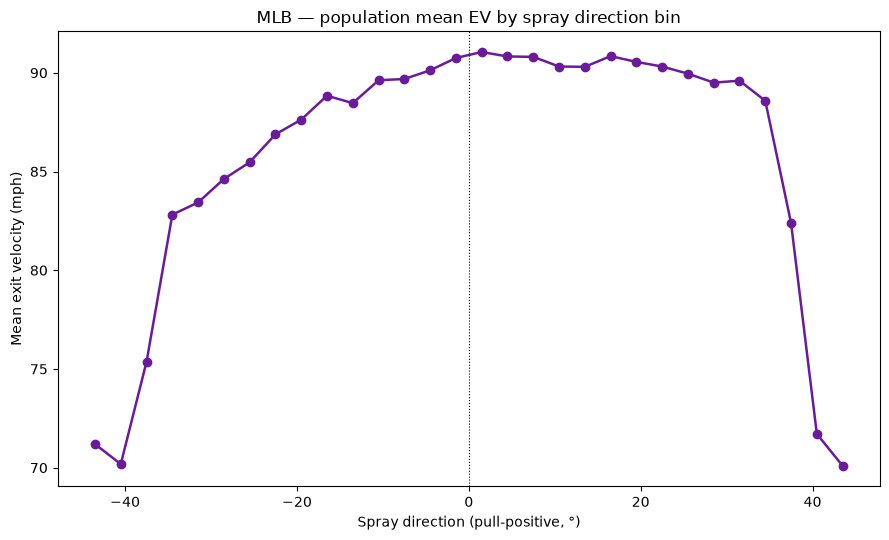

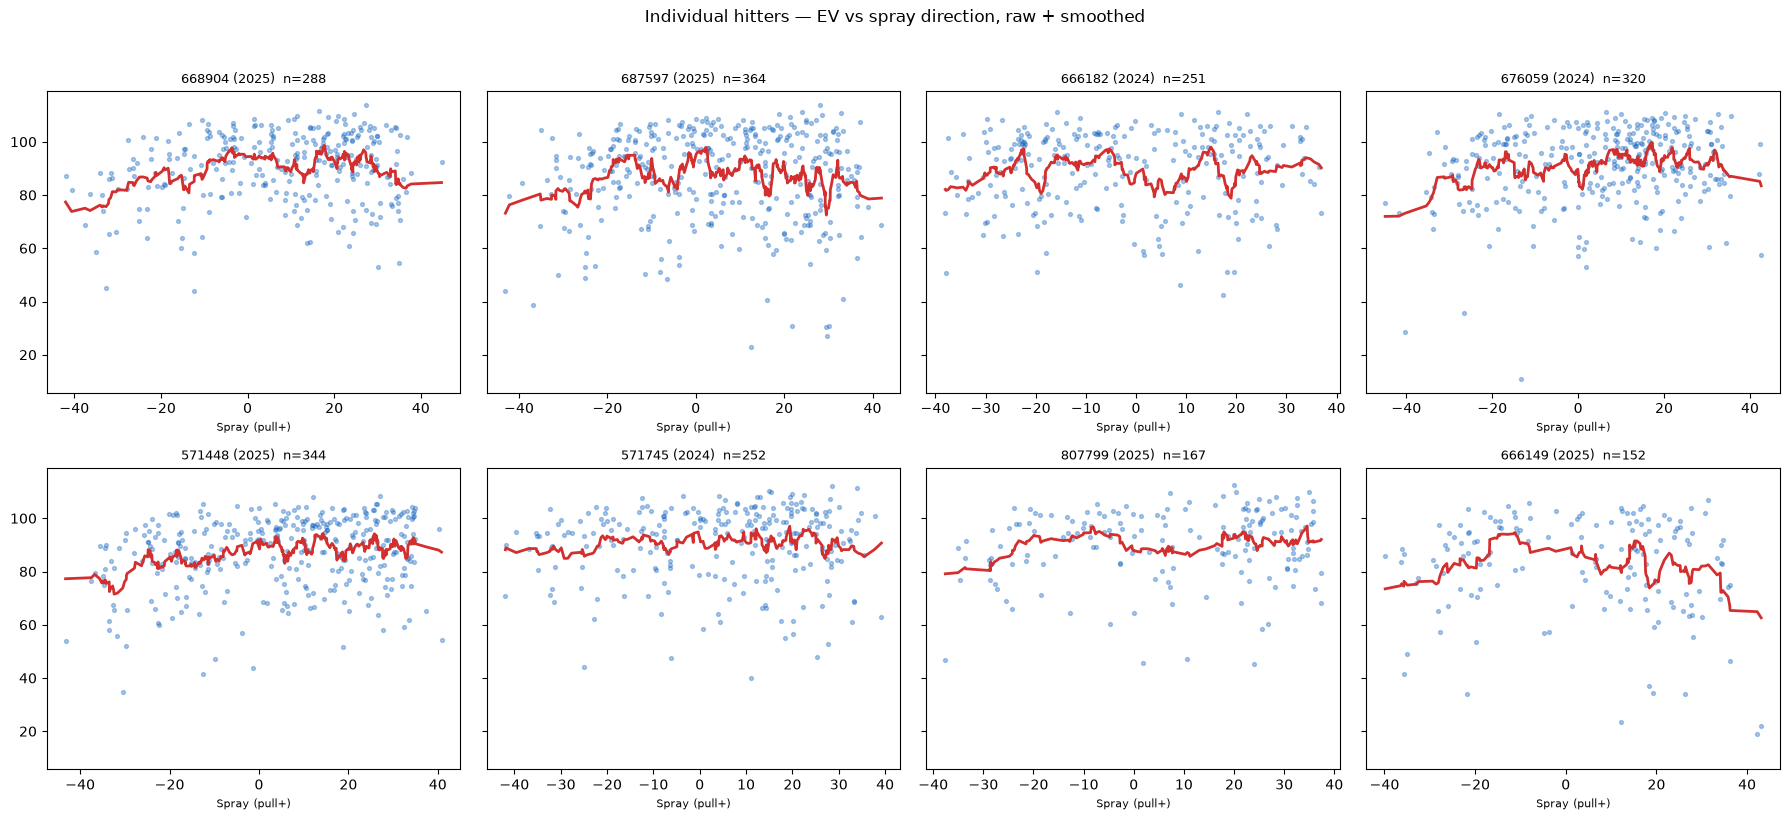

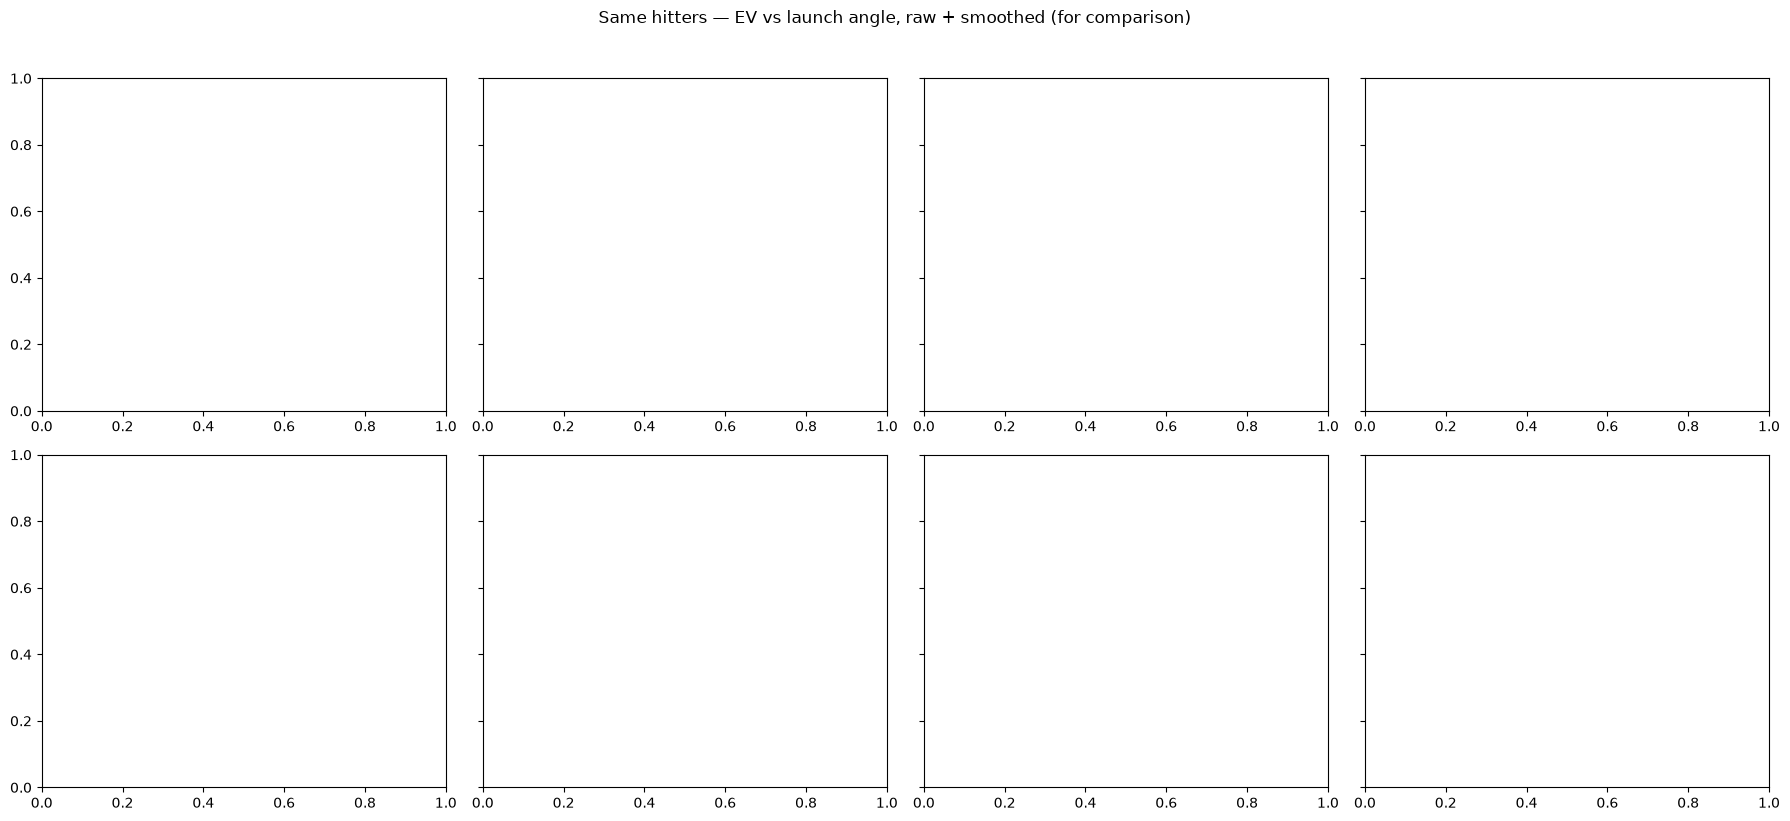

In [46]:
# ── 1. Population-level EV vs spray_pull shape ────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5.5))

bin_edges = np.linspace(SPRAY_MIN, SPRAY_MAX, 31)
bin_mids  = (bin_edges[:-1] + bin_edges[1:]) / 2
binned = pd.cut(mlb["spray_pull"], bin_edges)
mean_ev_by_bin = mlb.groupby(binned, observed=True)["launch_speed"].mean()
n_by_bin       = mlb.groupby(binned, observed=True)["launch_speed"].size()

ax.plot(bin_mids, mean_ev_by_bin.values, "o-", color="#6A1B9A", linewidth=1.8)
ax.set_xlabel("Spray direction (pull-positive, °)")
ax.set_ylabel("Mean exit velocity (mph)")
ax.set_title("MLB — population mean EV by spray direction bin")
ax.axvline(0, color="black", linewidth=0.8, linestyle=":")
plt.tight_layout(); plt.show()

# ── 2. Individual-hitter shapes — this is the important one ───────────────────
# Pick several qualified hitters at random and overlay their own EV-vs-spray
# curves. If these are noisy / non-smooth / barely peaked compared to the
# population curve, that visually confirms high per-swing noise on this axis.
sample_batters = (qual[qual["n_bbe"] >= 150]
                  .sample(8, random_state=1)[["batter", "season"]]
                  .itertuples(index=False))

fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=True)
for ax, (b, s) in zip(axes.flat, sample_batters):
    g = mlb[(mlb["batter"] == b) & (mlb["season"] == s)].dropna(
        subset=["spray_pull", "launch_speed"])
    g = g[(g["spray_pull"] >= SPRAY_MIN) & (g["spray_pull"] <= SPRAY_MAX)]

    ax.scatter(g["spray_pull"], g["launch_speed"], s=8, alpha=0.35, color="#1565C0")

    # Overlay a light LOESS-style smooth (rolling mean over sorted x) for visual aid
    g_sorted = g.sort_values("spray_pull")
    roll = g_sorted["launch_speed"].rolling(15, center=True, min_periods=5).mean()
    ax.plot(g_sorted["spray_pull"], roll, color="#D32F2F", linewidth=2)

    ax.set_title(f"{b} ({s})  n={len(g)}", fontsize=9)
    ax.set_xlabel("Spray (pull+)", fontsize=8)
plt.suptitle("Individual hitters — EV vs spray direction, raw + smoothed", y=1.02)
plt.tight_layout(); plt.show()

# ── 3. Same thing for PAA's axis, for direct comparison ──────────────────────
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=True)
for ax, (b, s) in zip(axes.flat, sample_batters):
    g = mlb[(mlb["batter"] == b) & (mlb["season"] == s)].dropna(
        subset=["launch_angle", "launch_speed"])
    g = g[(g["launch_angle"] >= ANGLE_MIN) & (g["launch_angle"] <= ANGLE_MAX)]

    ax.scatter(g["launch_angle"], g["launch_speed"], s=8, alpha=0.35, color="#2E7D32")
    g_sorted = g.sort_values("launch_angle")
    roll = g_sorted["launch_speed"].rolling(15, center=True, min_periods=5).mean()
    ax.plot(g_sorted["launch_angle"], roll, color="#D32F2F", linewidth=2)

    ax.set_title(f"{b} ({s})  n={len(g)}", fontsize=9)
    ax.set_xlabel("Launch angle", fontsize=8)
plt.suptitle("Same hitters — EV vs launch angle, raw + smoothed (for comparison)", y=1.02)
plt.tight_layout(); plt.show()

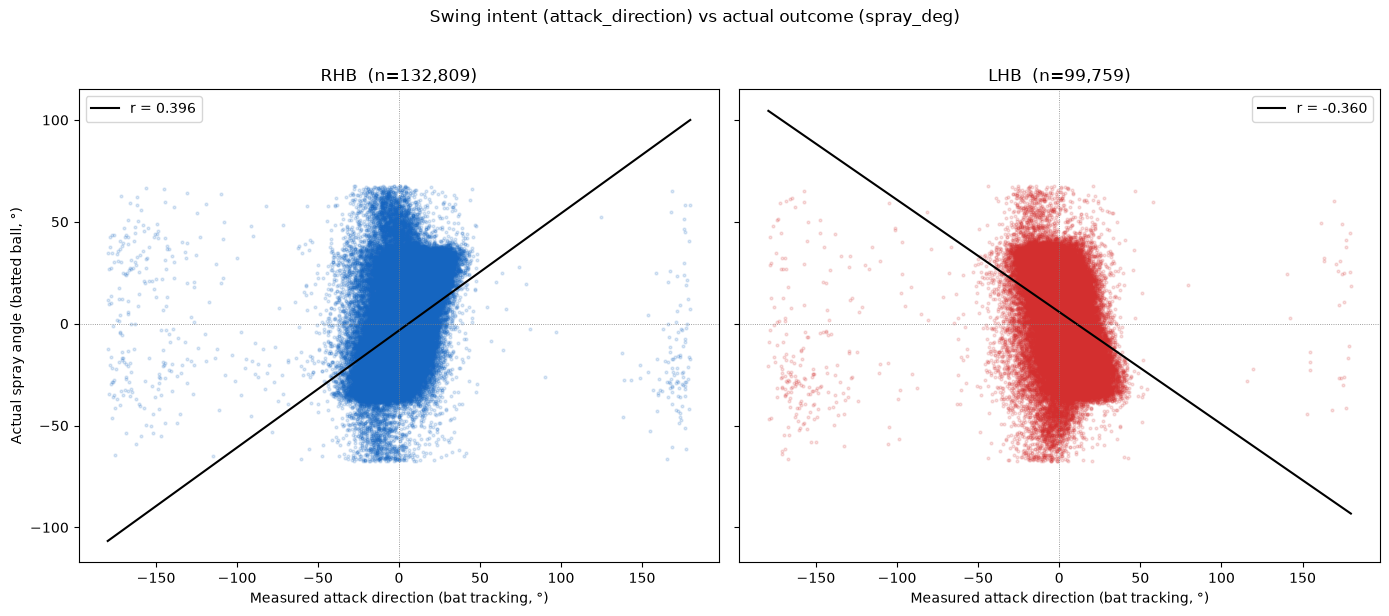

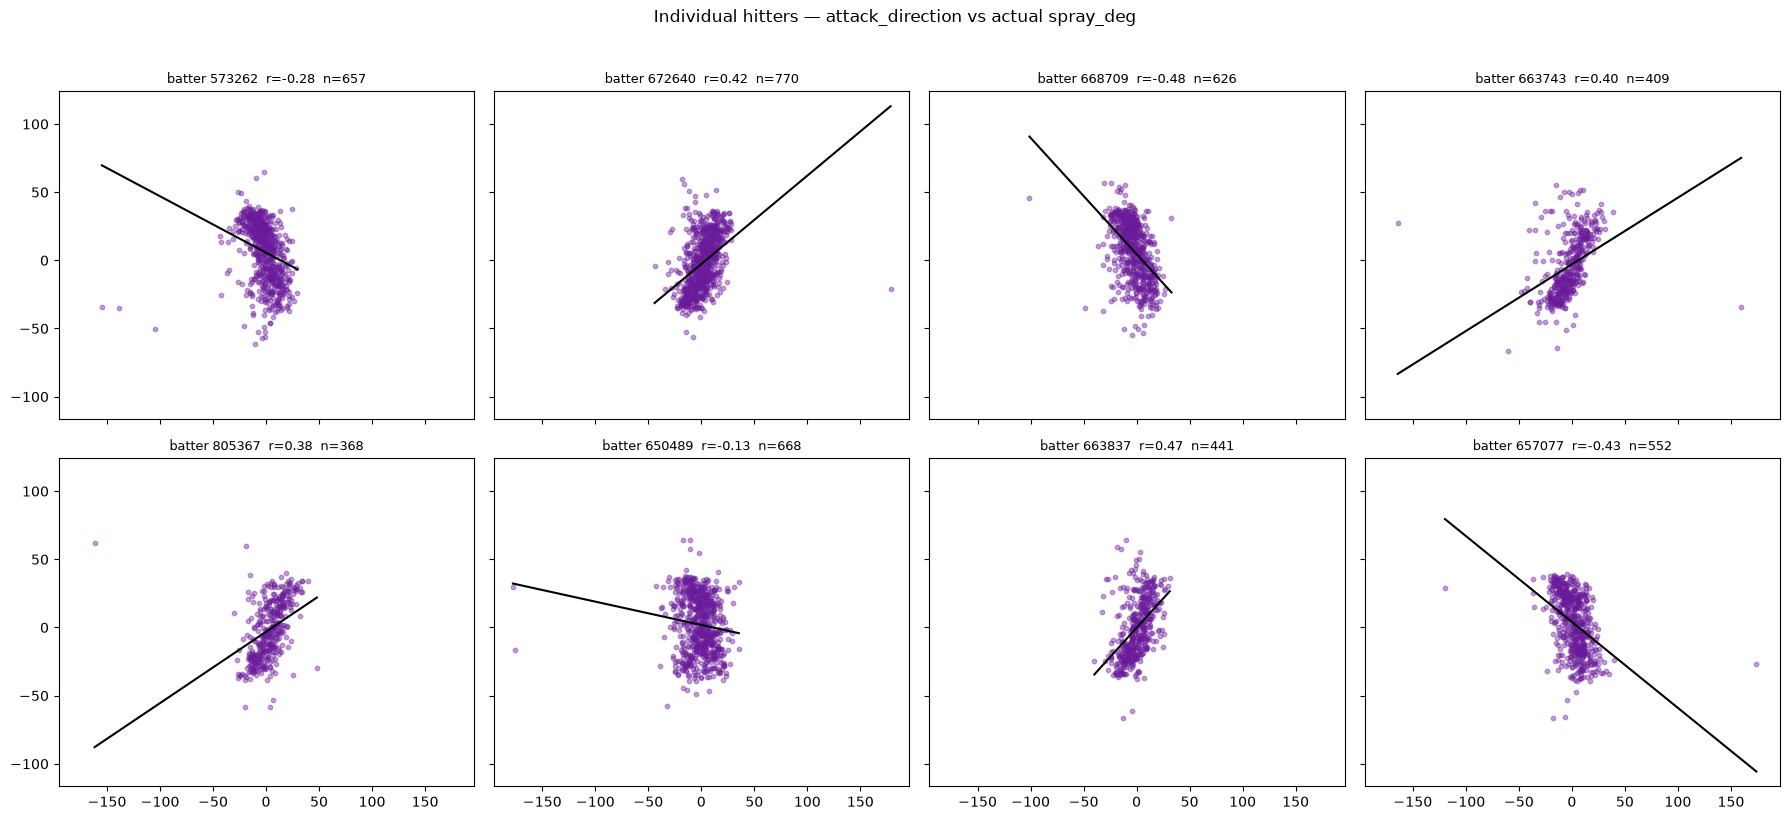

── Std of actual spray_deg WITHIN each attack_direction bin ──
(this is the per-swing 'noise floor' between intent and outcome)
stand  ad_bin    
L      (-60, -50]   21.300
       (-50, -40]   26.160
       (-40, -30]   25.480
       (-30, -20]   23.130
       (-20, -10]   19.410
       (-10, 0]     19.850
       (0, 10]      19.520
       (10, 20]     17.970
       (20, 30]     15.700
       (30, 40]     14.860
       (40, 50]     21.600
       (50, 60]     35.710
R      (-60, -50]   28.580
       (-50, -40]   25.020
       (-40, -30]   25.430
       (-30, -20]   21.590
       (-20, -10]   19.240
       (-10, 0]     19.400
       (0, 10]      18.500
       (10, 20]     16.880
       (20, 30]     15.150
       (30, 40]     14.590
       (40, 50]     22.350
       (50, 60]     14.500


In [47]:
# ── Measured attack_direction vs actual spray_deg, per handedness ────────────
ad_bbe = raw[
    (raw["type"] == "X") &
    raw["attack_direction"].notna() &
    raw["hc_x"].notna() & raw["hc_y"].notna() &
    raw["stand"].notna()
].copy()

ad_bbe["spray_deg"] = np.degrees(
    np.arctan((ad_bbe["hc_x"] - 125.42) / (198.27 - ad_bbe["hc_y"]))
) * 0.75

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for ax, side in zip(axes, ["R", "L"]):
    sub = ad_bbe[ad_bbe["stand"] == side]
    ax.scatter(sub["attack_direction"], sub["spray_deg"],
              s=4, alpha=0.15, color="#1565C0" if side == "R" else "#D32F2F")

    # Linear fit for reference
    m, b, r, p, se = stats.linregress(sub["attack_direction"], sub["spray_deg"])
    xs = np.linspace(sub["attack_direction"].min(), sub["attack_direction"].max(), 100)
    ax.plot(xs, m * xs + b, color="black", linewidth=1.5,
           label=f"r = {r:.3f}")

    ax.set_xlabel("Measured attack direction (bat tracking, °)")
    ax.set_title(f"{side}HB  (n={len(sub):,})")
    ax.legend()
    ax.axhline(0, color="gray", linewidth=0.6, linestyle=":")
    ax.axvline(0, color="gray", linewidth=0.6, linestyle=":")
axes[0].set_ylabel("Actual spray angle (batted ball, °)")
plt.suptitle("Swing intent (attack_direction) vs actual outcome (spray_deg)", y=1.02)
plt.tight_layout(); plt.show()

# ── Same, but per-batter to see if the scatter is systematic or genuinely random ──
sample_batters_ad = (
    ad_bbe.groupby("batter").size()
    .pipe(lambda s: s[s >= 100])
    .sample(8, random_state=1).index
)

fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=True, sharey=True)
for ax, b in zip(axes.flat, sample_batters_ad):
    sub = ad_bbe[ad_bbe["batter"] == b]
    ax.scatter(sub["attack_direction"], sub["spray_deg"], s=10, alpha=0.4, color="#6A1B9A")
    m, bb, r, p, se = stats.linregress(sub["attack_direction"], sub["spray_deg"])
    xs = np.linspace(sub["attack_direction"].min(), sub["attack_direction"].max(), 50)
    ax.plot(xs, m * xs + bb, color="black", linewidth=1.5)
    ax.set_title(f"batter {b}  r={r:.2f}  n={len(sub)}", fontsize=9)
plt.suptitle("Individual hitters — attack_direction vs actual spray_deg", y=1.02)
plt.tight_layout(); plt.show()

# ── Residual spread: how much does actual spray vary for a FIXED attack_direction? ──
# This isolates "contact-to-contact noise" from "true swing intent variance"
ad_bbe["ad_bin"] = pd.cut(ad_bbe["attack_direction"], bins=np.arange(-60, 61, 10))
resid_by_bin = ad_bbe.groupby(["stand", "ad_bin"], observed=True)["spray_deg"].std()
print("── Std of actual spray_deg WITHIN each attack_direction bin ──")
print("(this is the per-swing 'noise floor' between intent and outcome)")
print(resid_by_bin.round(2).to_string())

Dropped 701 rows with |attack_direction| > 50°
Dropped 4,120 rows with |spray_deg| > 45°

── Effect of outlier trimming on per-batter r ──
Mean r (raw):     0.106
Mean r (cleaned): 0.112
Mean points dropped per batter: 1.6 (0.5% of all BBE)


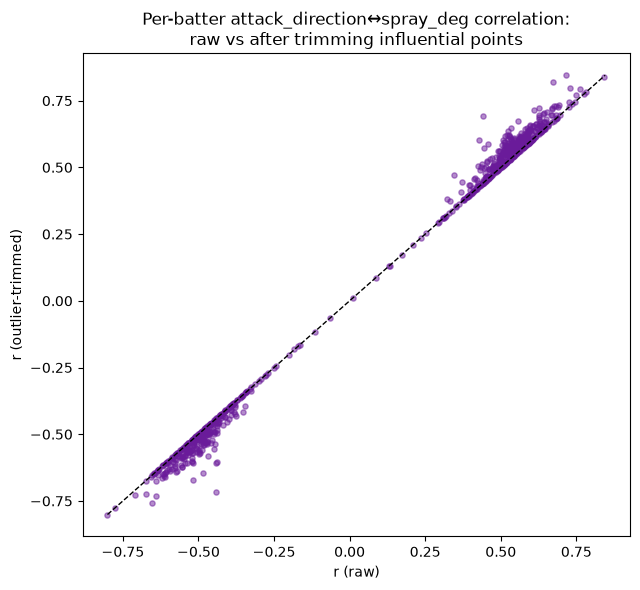

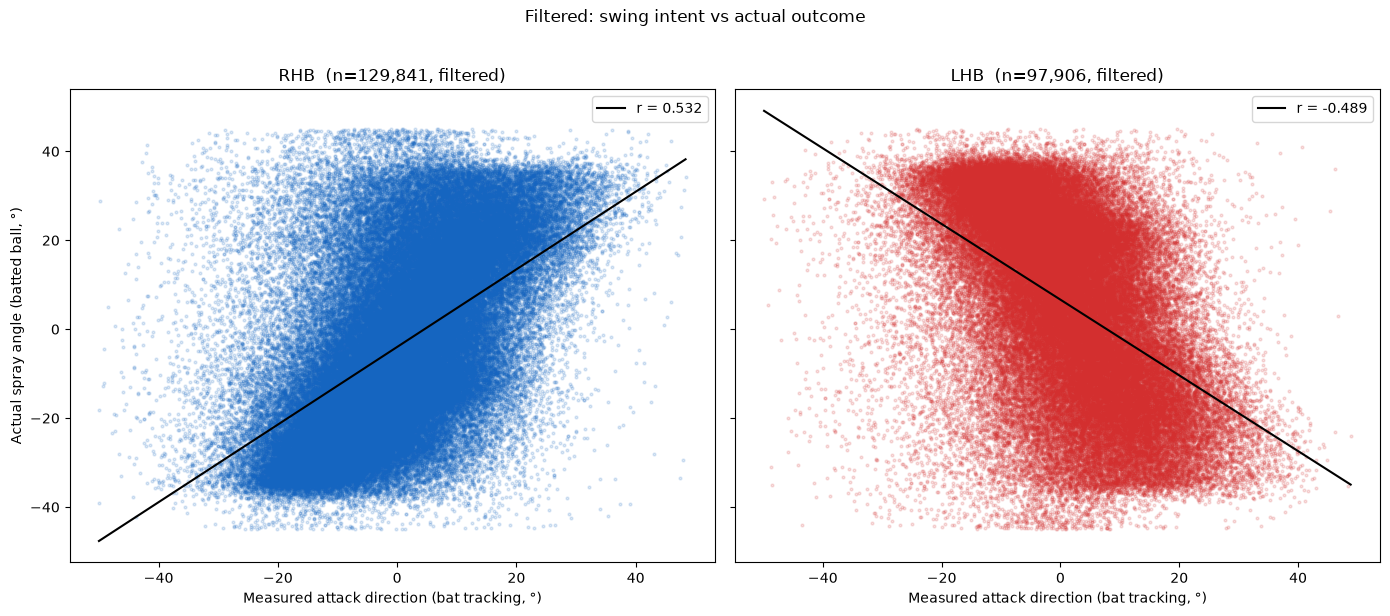

In [48]:
# ── Filter physically implausible attack_direction values ────────────────────
# ±50° is beyond any plausible bat path direction at contact — likely tracking
# artifacts (mis-ID'd swings, glitched frames) rather than real swings.
n_before = len(ad_bbe)
ad_bbe = ad_bbe[ad_bbe["attack_direction"].between(-50, 50)].copy()
print(f"Dropped {n_before - len(ad_bbe):,} rows with |attack_direction| > 50°")

# spray_deg itself should also be capped at the physical foul-line limits
n_before = len(ad_bbe)
ad_bbe = ad_bbe[ad_bbe["spray_deg"].between(-45, 45)].copy()
print(f"Dropped {n_before - len(ad_bbe):,} rows with |spray_deg| > 45°")


# ── Robust per-batter fits: flag and exclude influential points ──────────────
def robust_batter_fit(sub, resid_threshold=3.0):
    """
    Fit attack_direction -> spray_deg, then refit after dropping points with
    standardized residuals beyond resid_threshold (simple one-pass outlier
    trim — not full Cook's distance, but catches the worst offenders without
    needing statsmodels).
    """
    if len(sub) < 20:
        return None

    m, b, r, p, se = stats.linregress(sub["attack_direction"], sub["spray_deg"])
    pred = m * sub["attack_direction"] + b
    resid = sub["spray_deg"] - pred
    resid_z = (resid - resid.mean()) / resid.std()

    clean = sub[resid_z.abs() <= resid_threshold]
    n_dropped = len(sub) - len(clean)

    if len(clean) < 20:
        return None

    m2, b2, r2, p2, se2 = stats.linregress(clean["attack_direction"], clean["spray_deg"])
    return {"r_raw": r, "r_clean": r2, "n_raw": len(sub),
           "n_clean": len(clean), "n_dropped": n_dropped}


robust_results = []
for (b, s), g in ad_bbe.groupby(["batter", "stand"]):
    res = robust_batter_fit(g)
    if res:
        res["batter"] = b
        res["stand"] = s
        robust_results.append(res)

robust_df = pd.DataFrame(robust_results)
print(f"\n── Effect of outlier trimming on per-batter r ──")
print(f"Mean r (raw):     {robust_df['r_raw'].mean():.3f}")
print(f"Mean r (cleaned): {robust_df['r_clean'].mean():.3f}")
print(f"Mean points dropped per batter: {robust_df['n_dropped'].mean():.1f} "
      f"({(robust_df['n_dropped'].sum() / robust_df['n_raw'].sum()):.1%} of all BBE)")

# Show whether trimming meaningfully shifted individual batters, or was mostly cosmetic
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(robust_df["r_raw"], robust_df["r_clean"], s=14, alpha=0.5, color="#6A1B9A")
lims = [robust_df[["r_raw", "r_clean"]].min().min(), robust_df[["r_raw", "r_clean"]].max().max()]
ax.plot(lims, lims, "k--", linewidth=1)
ax.set_xlabel("r (raw)")
ax.set_ylabel("r (outlier-trimmed)")
ax.set_title("Per-batter attack_direction↔spray_deg correlation:\nraw vs after trimming influential points")
plt.tight_layout(); plt.show()


# ── Re-run the population-level scatter/fit on the filtered data ─────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for ax, side in zip(axes, ["R", "L"]):
    sub = ad_bbe[ad_bbe["stand"] == side]
    ax.scatter(sub["attack_direction"], sub["spray_deg"], s=4, alpha=0.15,
              color="#1565C0" if side == "R" else "#D32F2F")
    m, b, r, p, se = stats.linregress(sub["attack_direction"], sub["spray_deg"])
    xs = np.linspace(sub["attack_direction"].min(), sub["attack_direction"].max(), 100)
    ax.plot(xs, m * xs + b, color="black", linewidth=1.5, label=f"r = {r:.3f}")
    ax.set_xlabel("Measured attack direction (bat tracking, °)")
    ax.set_title(f"{side}HB  (n={len(sub):,}, filtered)")
    ax.legend()
axes[0].set_ylabel("Actual spray angle (batted ball, °)")
plt.suptitle("Filtered: swing intent vs actual outcome", y=1.02)
plt.tight_layout(); plt.show()

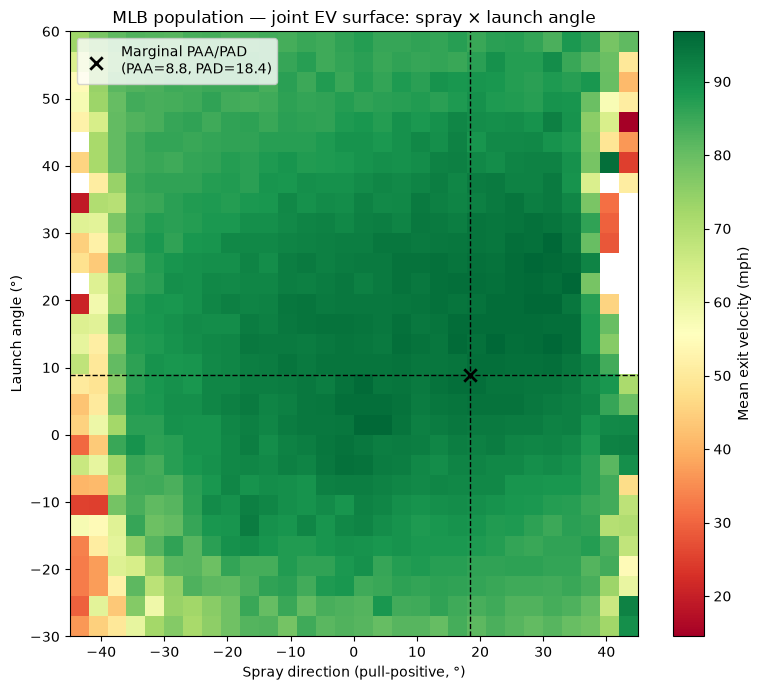

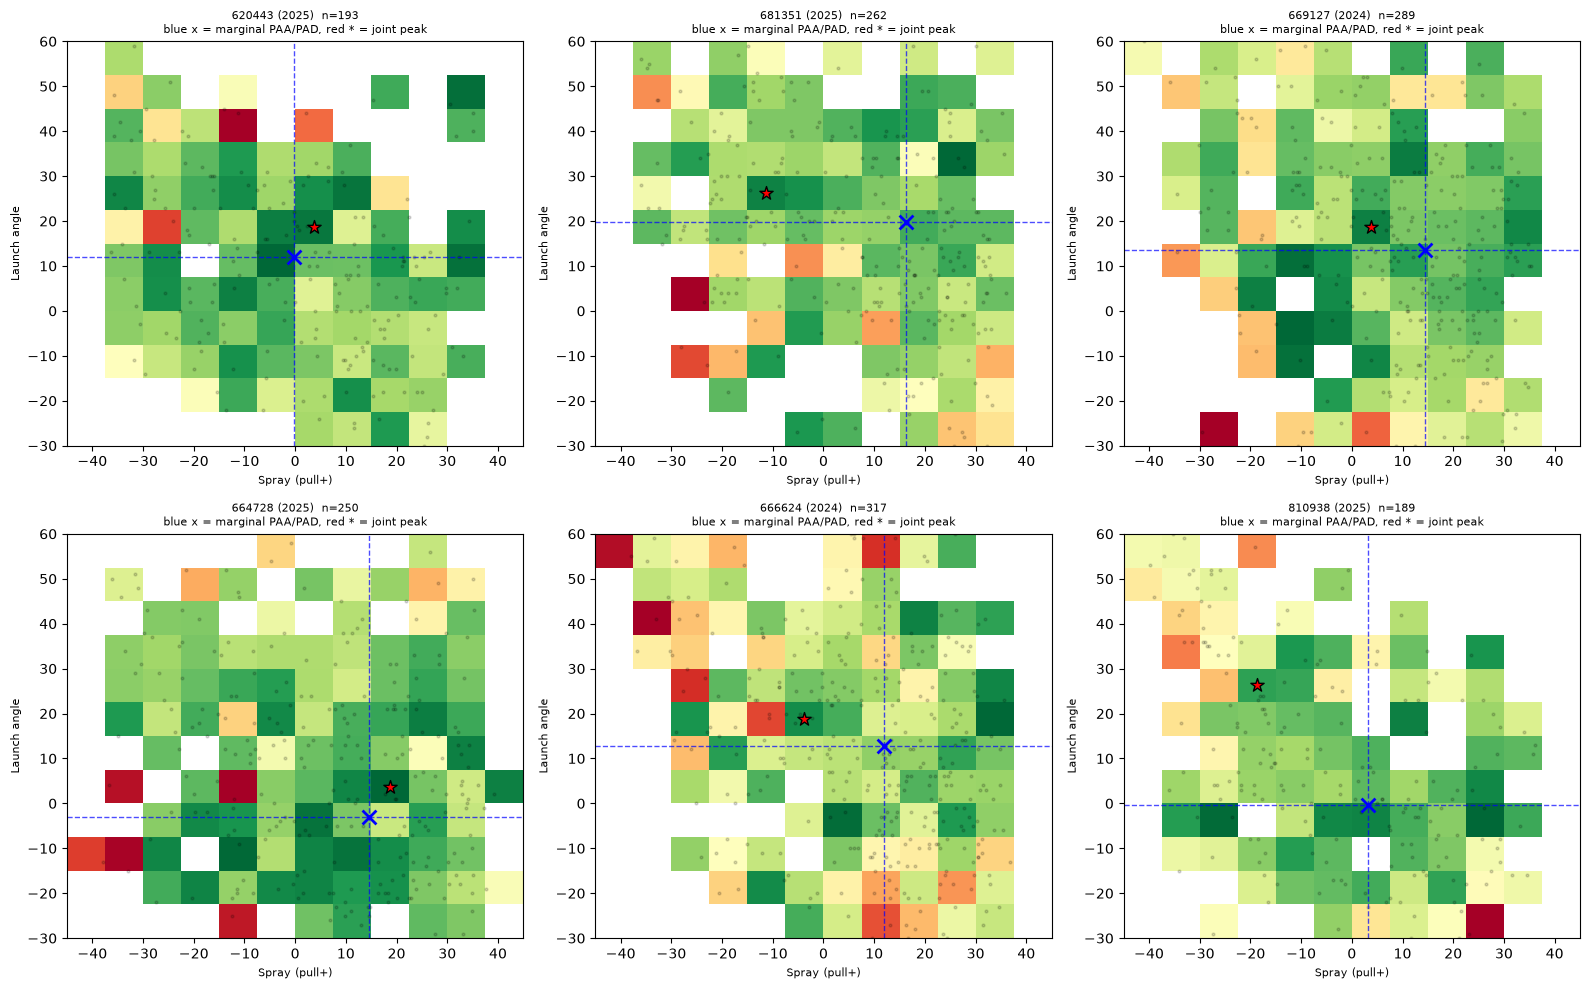

In [49]:
# ── Population-level: EV as a joint function of (spray_pull, launch_angle) ──
from scipy.stats import binned_statistic_2d

pop = mlb.dropna(subset=["spray_pull", "launch_angle", "launch_speed"])
pop = pop[
    pop["spray_pull"].between(SPRAY_MIN, SPRAY_MAX) &
    pop["launch_angle"].between(ANGLE_MIN, ANGLE_MAX)
]

stat, x_edge, y_edge, _ = binned_statistic_2d(
    pop["spray_pull"], pop["launch_angle"], pop["launch_speed"],
    statistic="mean", bins=[30, 30],
    range=[[SPRAY_MIN, SPRAY_MAX], [ANGLE_MIN, ANGLE_MAX]]
)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(stat.T, origin="lower", aspect="auto", cmap="RdYlGn",
              extent=[SPRAY_MIN, SPRAY_MAX, ANGLE_MIN, ANGLE_MAX])
plt.colorbar(im, ax=ax, label="Mean exit velocity (mph)")
ax.set_xlabel("Spray direction (pull-positive, °)")
ax.set_ylabel("Launch angle (°)")
ax.set_title("MLB population — joint EV surface: spray × launch angle")

# Mark the population's marginal PAA and PAD as a cross, for comparison
pop_paa = paa_of(pop.assign(launch_angle=pop["launch_angle"], launch_speed=pop["launch_speed"]))
pop_pad = pad_of(pop.assign(spray_pull=pop["spray_pull"], launch_speed=pop["launch_speed"]))
ax.axvline(pop_pad, color="black", linewidth=1, linestyle="--")
ax.axhline(pop_paa, color="black", linewidth=1, linestyle="--")
ax.scatter([pop_pad], [pop_paa], color="black", s=80, marker="x", linewidths=2,
          label=f"Marginal PAA/PAD\n(PAA={pop_paa:.1f}, PAD={pop_pad:.1f})")
ax.legend()
plt.tight_layout(); plt.show()


# ── Individual hitters: same joint surface, marginal cross overlay ───────────
sample_batters = (qual[qual["n_bbe"] >= 200]
                  .sample(6, random_state=3)[["batter", "season"]]
                  .itertuples(index=False))

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, (b, s) in zip(axes.flat, sample_batters):
    g = mlb[(mlb["batter"] == b) & (mlb["season"] == s)].dropna(
        subset=["spray_pull", "launch_angle", "launch_speed"])
    g = g[g["spray_pull"].between(SPRAY_MIN, SPRAY_MAX) &
         g["launch_angle"].between(ANGLE_MIN, ANGLE_MAX)]

    if len(g) < 50:
        continue

    stat_i, xe, ye, _ = binned_statistic_2d(
        g["spray_pull"], g["launch_angle"], g["launch_speed"],
        statistic="mean", bins=[12, 12],
        range=[[SPRAY_MIN, SPRAY_MAX], [ANGLE_MIN, ANGLE_MAX]]
    )

    im = ax.imshow(stat_i.T, origin="lower", aspect="auto", cmap="RdYlGn",
                   extent=[SPRAY_MIN, SPRAY_MAX, ANGLE_MIN, ANGLE_MAX])

    # Overlay raw points lightly for context
    ax.scatter(g["spray_pull"], g["launch_angle"], s=4, alpha=0.15, color="black")

    # Marginal PAA/PAD cross
    b_paa = paa_of(g)
    b_pad = pad_of(g)
    ax.axvline(b_pad, color="blue", linewidth=1, linestyle="--", alpha=0.7)
    ax.axhline(b_paa, color="blue", linewidth=1, linestyle="--", alpha=0.7)
    ax.scatter([b_pad], [b_paa], color="blue", s=100, marker="x", linewidths=2)

    # Joint peak: max of the smoothed 2D grid (find the best-supported cell,
    # e.g. require at least 3 BBE in the bin to avoid single-point spikes)
    counts, _, _ = np.histogram2d(g["spray_pull"], g["launch_angle"],
                                  bins=[xe, ye])
    valid_mask = counts >= 3
    stat_masked = np.where(valid_mask, stat_i, np.nan)
    if np.nanmax(stat_masked) == np.nanmax(stat_masked):  # not all-nan
        peak_idx = np.unravel_index(np.nanargmax(stat_masked), stat_masked.shape)
        peak_x = (xe[peak_idx[0]] + xe[peak_idx[0]+1]) / 2
        peak_y = (ye[peak_idx[1]] + ye[peak_idx[1]+1]) / 2
        ax.scatter([peak_x], [peak_y], color="red", s=100, marker="*",
                  linewidths=1, edgecolors="black")

    ax.set_title(f"{b} ({s})  n={len(g)}\nblue x = marginal PAA/PAD, red * = joint peak",
                fontsize=8)
    ax.set_xlabel("Spray (pull+)", fontsize=8)
    ax.set_ylabel("Launch angle", fontsize=8)

plt.tight_layout(); plt.show()

In [53]:
# ── Do fouls have usable exit velocity / direction data in Statcast? ─────────
fouls_raw = raw[raw["description"] == "foul"].copy()

print(f"Total foul rows: {len(fouls_raw):,}")
print(f"Fouls with launch_speed: {fouls_raw['launch_speed'].notna().sum():,} "
      f"({fouls_raw['launch_speed'].notna().mean():.1%})")
print(f"Fouls with hc_x/hc_y:    {(fouls_raw['hc_x'].notna() & fouls_raw['hc_y'].notna()).sum():,}")

Total foul rows: 262,638
Fouls with launch_speed: 229,042 (87.2%)
Fouls with hc_x/hc_y:    0


Hard-hit fouls (EV≥95): 0
Hard-hit BBE   (EV≥95): 101,242


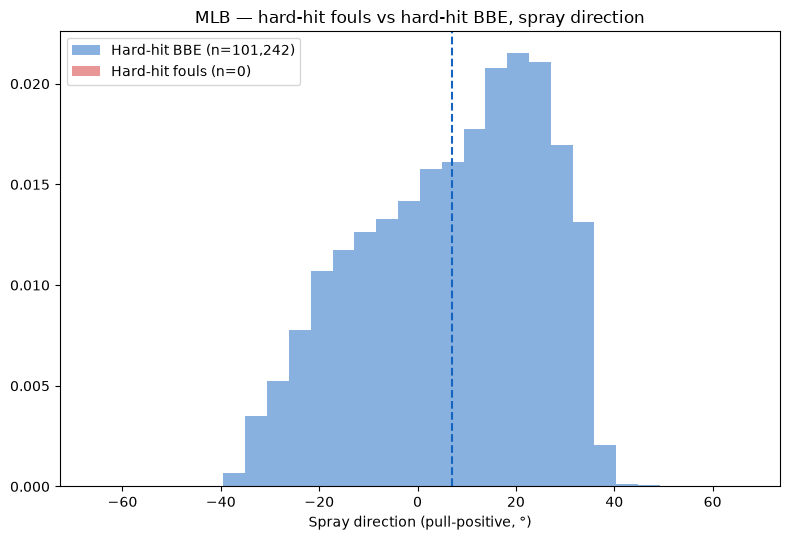


Mean spray_pull — hard-hit BBE:   7.0°
Mean spray_pull — hard-hit fouls: nan°


In [54]:
HARD_HIT_THRESH = 95

fouls_hh = fouls_raw[
    fouls_raw["launch_speed"].notna() &
    fouls_raw["hc_x"].notna() & fouls_raw["hc_y"].notna() &
    fouls_raw["stand"].notna() &
    (fouls_raw["launch_speed"] >= HARD_HIT_THRESH)
].copy()

fouls_hh["spray_deg"] = np.degrees(
    np.arctan((fouls_hh["hc_x"] - 125.42) / (198.27 - fouls_hh["hc_y"]))
) * 0.75
fouls_hh["spray_pull"] = np.where(fouls_hh["stand"] == "R",
                                 -fouls_hh["spray_deg"], fouls_hh["spray_deg"])

bbe_hh = mlb[mlb["launch_speed"] >= HARD_HIT_THRESH].copy()

print(f"Hard-hit fouls (EV≥{HARD_HIT_THRESH}): {len(fouls_hh):,}")
print(f"Hard-hit BBE   (EV≥{HARD_HIT_THRESH}): {len(bbe_hh):,}")

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.hist(bbe_hh["spray_pull"], bins=30, alpha=0.5, density=True,
       color="#1565C0", label=f"Hard-hit BBE (n={len(bbe_hh):,})")
ax.hist(fouls_hh["spray_pull"], bins=30, alpha=0.5, density=True,
       color="#D32F2F", label=f"Hard-hit fouls (n={len(fouls_hh):,})")
ax.axvline(bbe_hh["spray_pull"].mean(), color="#1565C0", linestyle="--")
ax.axvline(fouls_hh["spray_pull"].mean(), color="#D32F2F", linestyle="--")
ax.set_xlabel("Spray direction (pull-positive, °)")
ax.set_title("MLB — hard-hit fouls vs hard-hit BBE, spray direction")
ax.legend()
plt.tight_layout(); plt.show()

print(f"\nMean spray_pull — hard-hit BBE:   {bbe_hh['spray_pull'].mean():.1f}°")
print(f"Mean spray_pull — hard-hit fouls: {fouls_hh['spray_pull'].mean():.1f}°")

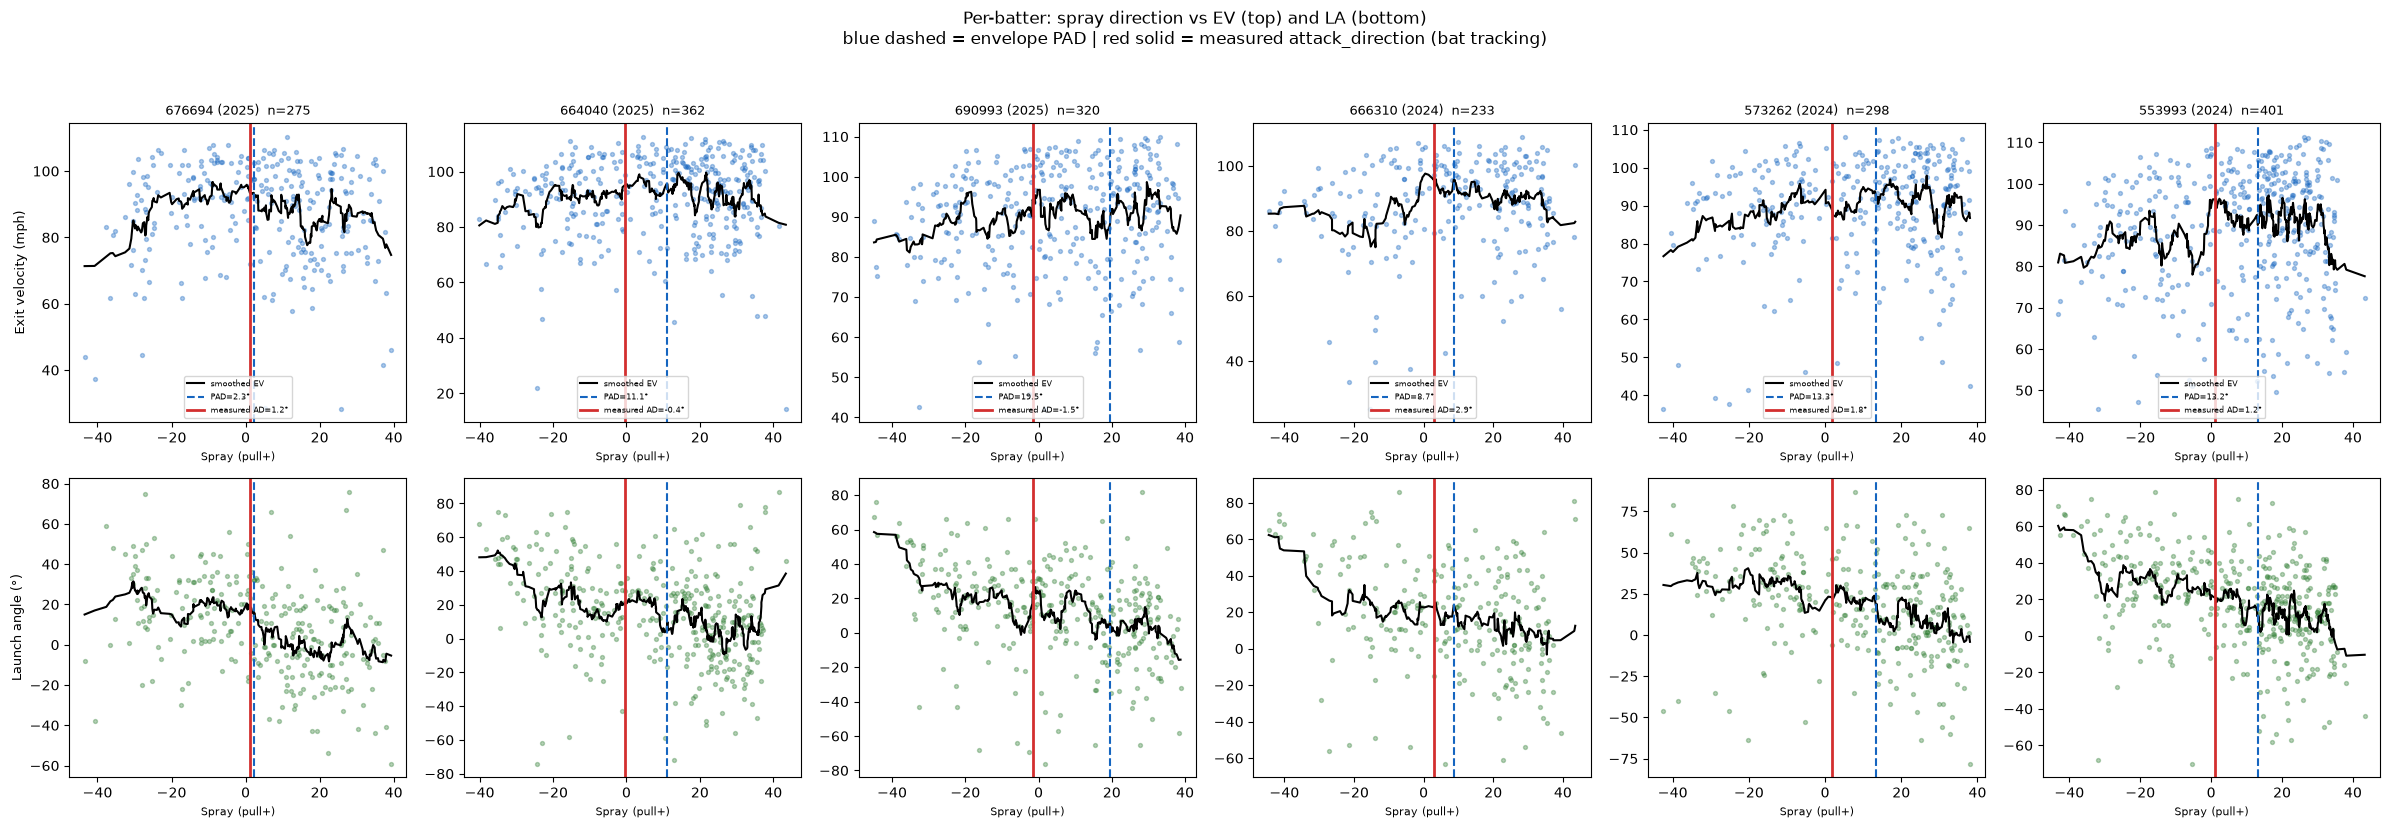

In [56]:
# ── Per-batter: spray angle vs EV, spray angle vs LA, with measured attack_direction ──
# Re-derive the empirical sign convention (same as the original validation cell)
signs = {}
for side in ["R", "L"]:
    sub = ad_bbe[ad_bbe["stand"] == side]
    r = sub[["attack_direction", "spray_deg"]].corr().iloc[0, 1]
    signs[side] = np.sign(r)

ad_bbe["ad_pull"] = np.where(
    ad_bbe["stand"] == "R",
    -ad_bbe["attack_direction"] * signs["R"],
     ad_bbe["attack_direction"] * signs["L"],
)
# Need per-batter measured attack_direction, mirrored to pull-positive using
# the same empirical sign convention derived earlier (signs["R"]/signs["L"])
ad_batter_mean = (
    ad_bbe.groupby("batter")
    .agg(ad_pull_mean=("ad_pull", "mean"), n_swings=("ad_pull", "count"))
    .reset_index()
)

# Pick hitters with both a solid BBE sample and a solid measured-swing sample
candidates = (
    qual[qual["n_bbe"] >= 150]
    .merge(ad_batter_mean[ad_batter_mean["n_swings"] >= 100], on="batter")
)
sample_batters = candidates.sample(6, random_state=4)[["batter", "season"]].itertuples(index=False)

fig, axes = plt.subplots(2, 6, figsize=(24, 8))

for col, (b, s) in enumerate(sample_batters):
    g = mlb[(mlb["batter"] == b) & (mlb["season"] == s)].dropna(
        subset=["spray_pull", "launch_speed", "launch_angle"])
    g = g[g["spray_pull"].between(SPRAY_MIN, SPRAY_MAX)]
    if len(g) < 50:
        continue

    b_pad = pad_of(g)
    b_ad  = ad_batter_mean.loc[ad_batter_mean["batter"] == b, "ad_pull_mean"].values[0]

    # Row 1: spray vs EV
    ax1 = axes[0, col]
    ax1.scatter(g["spray_pull"], g["launch_speed"], s=8, alpha=0.35, color="#1565C0")
    g_sorted = g.sort_values("spray_pull")
    roll_ev = g_sorted["launch_speed"].rolling(15, center=True, min_periods=5).mean()
    ax1.plot(g_sorted["spray_pull"], roll_ev, color="black", linewidth=1.5, label="smoothed EV")
    ax1.axvline(b_pad, color="#1565C0", linestyle="--", linewidth=1.5, label=f"PAD={b_pad:.1f}°")
    ax1.axvline(b_ad, color="#D32F2F", linestyle="-", linewidth=2, label=f"measured AD={b_ad:.1f}°")
    ax1.set_title(f"{b} ({s})  n={len(g)}", fontsize=9)
    ax1.set_xlabel("Spray (pull+)", fontsize=8)
    if col == 0:
        ax1.set_ylabel("Exit velocity (mph)", fontsize=9)
    ax1.legend(fontsize=6, loc="lower center")

    # Row 2: spray vs LA
    ax2 = axes[1, col]
    ax2.scatter(g["spray_pull"], g["launch_angle"], s=8, alpha=0.35, color="#2E7D32")
    roll_la = g_sorted["launch_angle"].rolling(15, center=True, min_periods=5).mean()
    ax2.plot(g_sorted["spray_pull"], roll_la, color="black", linewidth=1.5)
    ax2.axvline(b_pad, color="#1565C0", linestyle="--", linewidth=1.5)
    ax2.axvline(b_ad, color="#D32F2F", linestyle="-", linewidth=2)
    ax2.set_xlabel("Spray (pull+)", fontsize=8)
    if col == 0:
        ax2.set_ylabel("Launch angle (°)", fontsize=9)

plt.suptitle(
    "Per-batter: spray direction vs EV (top) and LA (bottom)\n"
    "blue dashed = envelope PAD | red solid = measured attack_direction (bat tracking)",
    y=1.03
)
plt.tight_layout(); plt.show()

In [57]:
# ── Confirm contact-depth sign convention empirically ────────────────────────
depth_col = "intercept_ball_minus_batter_pos_y_inches"

depth_check = mlb.dropna(subset=[depth_col, "spray_pull"])
print(depth_check[depth_col].describe())

# Correlate contact depth with measured attack_direction directly — if
# "more front" contact tracks toward the batter's true swing direction more
# tightly than "more back" contact does, that's the diagnostic confirmation.
merged_depth = depth_check.merge(
    ad_bbe[["batter", "ad_pull"]].drop_duplicates("batter"),
    on="batter", how="inner"
)
r_depth_ad = merged_depth[[depth_col, "ad_pull"]].corr().iloc[0, 1]
print(f"\ncontact depth vs measured attack_direction (batter-level): r = {r_depth_ad:.3f}")

count   231789.000
mean        29.993
std          7.813
min         -4.320
25%         24.721
50%         29.849
75%         35.160
max         71.281
Name: intercept_ball_minus_batter_pos_y_inches, dtype: Float64

contact depth vs measured attack_direction (batter-level): r = 0.065


Front-contact spray vs MAD:  r = -0.087   mean bias = +17.94°
Envelope PAD vs MAD:         r = 0.461   mean bias = +11.23°


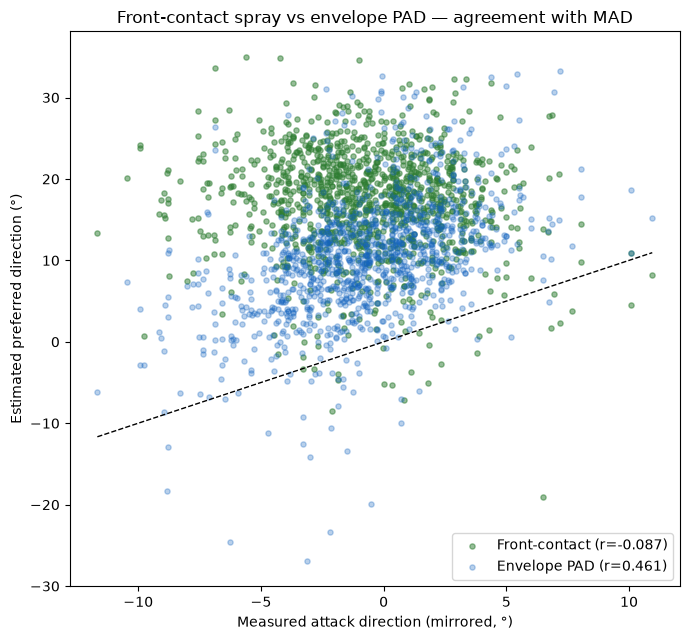

In [58]:
# ── Frontmost-contact spray direction (front-K%) vs MAD vs envelope PAD ──────
FRONT_PCT = 0.10  # top 20% most out-front contact, mirrors the envelope's top-20% logic

def front_contact_spray(g, depth_col="intercept_ball_minus_batter_pos_y_inches",
                        spray_col="spray_pull", front_pct=FRONT_PCT):
    gc = g.dropna(subset=[depth_col, spray_col])
    if len(gc) < 15:
        return np.nan
    k = max(5, int(np.ceil(front_pct * len(gc))))
    # NOTE: confirm sign from the check above — flip nlargest/nsmallest if
    # "front" turns out to be the smaller/negative end of this column
    front = gc.nlargest(k, depth_col)
    return front[spray_col].mean()


results = []
for (b, s), g in mlb.groupby(["batter", "season"]):
    fcs = front_contact_spray(g)
    pad = pad_of(g)
    results.append({"batter": b, "season": s, "front_contact_spray": fcs, "PAD": pad})

fc_df = pd.DataFrame(results).dropna()
fc_df = fc_df.merge(ad_batter_mean[["batter", "ad_pull_mean"]], on="batter", how="inner")

r_fc_mad  = fc_df[["front_contact_spray", "ad_pull_mean"]].corr().iloc[0, 1]
r_pad_mad = fc_df[["PAD", "ad_pull_mean"]].corr().iloc[0, 1]

bias_fc  = (fc_df["front_contact_spray"] - fc_df["ad_pull_mean"]).mean()
bias_pad = (fc_df["PAD"] - fc_df["ad_pull_mean"]).mean()

print(f"Front-contact spray vs MAD:  r = {r_fc_mad:.3f}   mean bias = {bias_fc:+.2f}°")
print(f"Envelope PAD vs MAD:         r = {r_pad_mad:.3f}   mean bias = {bias_pad:+.2f}°")

fig, ax = plt.subplots(figsize=(7, 6.5))
ax.scatter(fc_df["ad_pull_mean"], fc_df["front_contact_spray"],
          s=14, alpha=0.5, color="#2E7D32", label=f"Front-contact (r={r_fc_mad:.3f})")
ax.scatter(fc_df["ad_pull_mean"], fc_df["PAD"],
          s=14, alpha=0.3, color="#1565C0", label=f"Envelope PAD (r={r_pad_mad:.3f})")
lims = [fc_df["ad_pull_mean"].min(), fc_df["ad_pull_mean"].max()]
ax.plot(lims, lims, "k--", linewidth=1)
ax.set_xlabel("Measured attack direction (mirrored, °)")
ax.set_ylabel("Estimated preferred direction (°)")
ax.set_title("Front-contact spray vs envelope PAD — agreement with MAD")
ax.legend()
plt.tight_layout(); plt.show()

In [59]:
print(f"contact depth vs measured attack_direction (batter-level): r = {r_depth_ad:.3f}")
print(mlb["intercept_ball_minus_batter_pos_y_inches"].describe())

contact depth vs measured attack_direction (batter-level): r = 0.065
count   231789.000
mean        29.993
std          7.813
min         -4.320
25%         24.721
50%         29.849
75%         35.160
max         71.281
Name: intercept_ball_minus_batter_pos_y_inches, dtype: Float64


In [60]:
# ── Test: does the front 10% specifically show tighter MAD agreement, ───────
# vs a matched random sample? (Tail effect, not a linear/aggregate one)

depth_col = "intercept_ball_minus_batter_pos_y_inches"

def front_pct_spray(g, front_pct, depth_col=depth_col, spray_col="spray_pull"):
    gc = g.dropna(subset=[depth_col, spray_col])
    if len(gc) < 20:
        return np.nan
    k = max(5, int(np.ceil(front_pct * len(gc))))
    front = gc.nlargest(k, depth_col)   # confirm this is really "front" below
    return front[spray_col].mean()

def random_pct_spray(g, pct, seed, spray_col="spray_pull"):
    gc = g.dropna(subset=[depth_col, spray_col])
    if len(gc) < 20:
        return np.nan
    k = max(5, int(np.ceil(pct * len(gc))))
    return gc.sample(k, random_state=seed)[spray_col].mean()


rows = []
for (b, s), g in mlb.groupby(["batter", "season"]):
    front10 = front_pct_spray(g, 0.10)
    rand10  = random_pct_spray(g, 0.10, seed=1)
    rows.append({"batter": b, "season": s, "front10_spray": front10, "rand10_spray": rand10})

tail_df = pd.DataFrame(rows).dropna()
tail_df = tail_df.merge(ad_batter_mean[["batter", "ad_pull_mean"]], on="batter", how="inner")

r_front10 = tail_df[["front10_spray", "ad_pull_mean"]].corr().iloc[0, 1]
r_rand10  = tail_df[["rand10_spray", "ad_pull_mean"]].corr().iloc[0, 1]

print(f"Front 10% (by depth) vs MAD:  r = {r_front10:.3f}")
print(f"Random 10% (control) vs MAD:  r = {r_rand10:.3f}")

Front 10% (by depth) vs MAD:  r = -0.083
Random 10% (control) vs MAD:  r = 0.217


In [61]:
# CORRECT: negative = out front, per the original notebook's own comment
def front_pct_spray_correct(g, front_pct, depth_col=depth_col, spray_col="spray_pull"):
    gc = g.dropna(subset=[depth_col, spray_col])
    if len(gc) < 20:
        return np.nan
    k = max(5, int(np.ceil(front_pct * len(gc))))
    front = gc.nsmallest(k, depth_col)   # nsmallest, not nlargest — front = negative
    return front[spray_col].mean()

rows = []
for (b, s), g in mlb.groupby(["batter", "season"]):
    front10_correct = front_pct_spray_correct(g, 0.10)
    rand10 = random_pct_spray(g, 0.10, seed=1)
    rows.append({"batter": b, "season": s, "front10_correct": front10_correct, "rand10_spray": rand10})

tail_df2 = pd.DataFrame(rows).dropna()
tail_df2 = tail_df2.merge(ad_batter_mean[["batter", "ad_pull_mean"]], on="batter", how="inner")

r_front10_correct = tail_df2[["front10_correct", "ad_pull_mean"]].corr().iloc[0, 1]
r_rand10          = tail_df2[["rand10_spray", "ad_pull_mean"]].corr().iloc[0, 1]

print(f"Front 10% (CORRECTED sign) vs MAD: r = {r_front10_correct:.3f}")
print(f"Random 10% (control) vs MAD:       r = {r_rand10:.3f}")

Front 10% (CORRECTED sign) vs MAD: r = 0.244
Random 10% (control) vs MAD:       r = 0.217


In [62]:
# ── Does front-10%-by-depth spray add signal beyond envelope PAD alone? ──────
# Test: does a simple two-feature linear blend (PAD + front10_correct) predict
# MAD better than PAD alone, mirroring how the original model used depth as
# an ADDITIONAL feature rather than a replacement.

combined = qual[["batter", "season", "PAD"]].merge(
    tail_df2[["batter", "season", "front10_correct", "ad_pull_mean"]],
    on=["batter", "season"]
).dropna()

from sklearn.linear_model import LinearRegression

X_pad_only = combined[["PAD"]].values
X_both     = combined[["PAD", "front10_correct"]].values
y          = combined["ad_pull_mean"].values

r2_pad_only = LinearRegression().fit(X_pad_only, y).score(X_pad_only, y)
r2_both     = LinearRegression().fit(X_both, y).score(X_both, y)

print(f"PAD alone            -> R² vs MAD: {r2_pad_only:.3f}")
print(f"PAD + front10_correct -> R² vs MAD: {r2_both:.3f}")

PAD alone            -> R² vs MAD: 0.273
PAD + front10_correct -> R² vs MAD: 0.297


In [63]:
# ── Build PAD_v2: envelope PAD + front-10%-by-depth spray, blended ──────────
from sklearn.linear_model import LinearRegression

blend_model = LinearRegression().fit(X_both, y)
coef_pad, coef_front10 = blend_model.coef_
intercept = blend_model.intercept_

print(f"PAD_v2 = {intercept:.3f} + {coef_pad:.3f}*PAD + {coef_front10:.3f}*front10_correct")

combined["PAD_v2"] = blend_model.predict(X_both)

# Sanity check: does PAD_v2 correlate with MAD better than either input alone?
r_pad_v2  = combined[["PAD_v2", "ad_pull_mean"]].corr().iloc[0, 1]
r_pad     = combined[["PAD", "ad_pull_mean"]].corr().iloc[0, 1]
r_front10 = combined[["front10_correct", "ad_pull_mean"]].corr().iloc[0, 1]

print(f"\nPAD alone:            r = {r_pad:.3f}")
print(f"front10_correct alone: r = {r_front10:.3f}")
print(f"PAD_v2 (blended):      r = {r_pad_v2:.3f}")

PAD_v2 = -1.906 + 0.247*PAD + 0.100*front10_correct

PAD alone:            r = 0.523
front10_correct alone: r = 0.284
PAD_v2 (blended):      r = 0.545


In [64]:
# ── Does correcting PAD using the LA-vs-spray slope reduce the systematic bias? ──
def la_corrected_pad(g, paa, pad_raw, la_col="launch_angle", spray_col="spray_pull"):
    """
    Regress spray on launch angle for this hitter, then ask: at THIS hitter's
    own PAA (their preferred launch angle), what spray value does the
    LA-vs-spray relationship predict? Compare that to raw envelope PAD.
    """
    gc = g.dropna(subset=[la_col, spray_col])
    if len(gc) < 30:
        return np.nan
    slope, intercept, r, p, se = stats.linregress(gc[la_col], gc[spray_col])
    return intercept + slope * paa

rows = []
for (b, s), g in mlb.groupby(["batter", "season"]):
    paa_val = paa_of(g)
    pad_val = pad_of(g)
    if np.isnan(paa_val) or np.isnan(pad_val):
        continue
    corrected = la_corrected_pad(g, paa_val, pad_val)
    rows.append({"batter": b, "season": s, "PAD": pad_val, "PAD_la_corrected": corrected})

la_corr_df = pd.DataFrame(rows).dropna().merge(
    ad_batter_mean[["batter", "ad_pull_mean"]], on="batter", how="inner"
)

r_pad_raw = la_corr_df[["PAD", "ad_pull_mean"]].corr().iloc[0, 1]
r_pad_lac = la_corr_df[["PAD_la_corrected", "ad_pull_mean"]].corr().iloc[0, 1]
bias_raw  = (la_corr_df["PAD"] - la_corr_df["ad_pull_mean"]).mean()
bias_lac  = (la_corr_df["PAD_la_corrected"] - la_corr_df["ad_pull_mean"]).mean()

print(f"Raw PAD:            r = {r_pad_raw:.3f}   mean bias = {bias_raw:+.2f}°")
print(f"LA-corrected PAD:   r = {r_pad_lac:.3f}   mean bias = {bias_lac:+.2f}°")

Raw PAD:            r = 0.469   mean bias = +11.28°
LA-corrected PAD:   r = 0.572   mean bias = +5.12°


In [65]:
combined_all = qual[["batter", "season", "PAD"]].merge(
    tail_df2[["batter", "season", "front10_correct"]], on=["batter", "season"]
).merge(
    la_corr_df[["batter", "season", "PAD_la_corrected"]], on=["batter", "season"]
).merge(
    ad_batter_mean[["batter", "ad_pull_mean"]], on="batter", how="inner"
).dropna()

X_stack = combined_all[["PAD", "front10_correct", "PAD_la_corrected"]].values
y_stack = combined_all["ad_pull_mean"].values

stack_model = LinearRegression().fit(X_stack, y_stack)
r2_stack = stack_model.score(X_stack, y_stack)
pred_stack = stack_model.predict(X_stack)
r_stack = np.corrcoef(pred_stack, y_stack)[0, 1]

print(f"Stacked model (PAD + front10 + LA-corrected): r = {r_stack:.3f}, R² = {r2_stack:.3f}")
print(f"Coefficients: {dict(zip(['PAD','front10_correct','PAD_la_corrected'], stack_model.coef_.round(3)))}")

Stacked model (PAD + front10 + LA-corrected): r = 0.654, R² = 0.427
Coefficients: {'PAD': np.float64(0.124), 'front10_correct': np.float64(-0.01), 'PAD_la_corrected': np.float64(0.466)}


In [66]:
# ── Simplified: does PAD + PAD_la_corrected alone match the 3-feature stack? ──
X_simple = combined_all[["PAD", "PAD_la_corrected"]].values
simple_model = LinearRegression().fit(X_simple, y_stack)
r2_simple = simple_model.score(X_simple, y_stack)
pred_simple = simple_model.predict(X_simple)
r_simple = np.corrcoef(pred_simple, y_stack)[0, 1]

print(f"PAD + PAD_la_corrected only: r = {r_simple:.3f}, R² = {r2_simple:.3f}")
print(f"Coefficients: {dict(zip(['PAD','PAD_la_corrected'], simple_model.coef_.round(3)))}")

PAD + PAD_la_corrected only: r = 0.653, R² = 0.427
Coefficients: {'PAD': np.float64(0.125), 'PAD_la_corrected': np.float64(0.458)}


In [67]:
# ── 1. Held-out validation (out-of-sample honesty check) ────────────────────
from sklearn.model_selection import train_test_split

idx = combined_all.index
train_idx, test_idx = train_test_split(idx, test_size=0.3, random_state=42)

X_tr = combined_all.loc[train_idx, ["PAD", "PAD_la_corrected"]].values
X_te = combined_all.loc[test_idx,  ["PAD", "PAD_la_corrected"]].values
y_tr = combined_all.loc[train_idx, "ad_pull_mean"].values
y_te = combined_all.loc[test_idx,  "ad_pull_mean"].values

held_out_model = LinearRegression().fit(X_tr, y_tr)
r_holdout = np.corrcoef(held_out_model.predict(X_te), y_te)[0, 1]

# Compare against raw PAD alone on the SAME held-out set, for a fair baseline
r_holdout_pad_only = np.corrcoef(
    combined_all.loc[test_idx, "PAD"], y_te
)[0, 1]

print(f"Held-out r — PAD alone:            {r_holdout_pad_only:.3f}")
print(f"Held-out r — PAD + LA-corrected:   {r_holdout:.3f}")

Held-out r — PAD alone:            0.489
Held-out r — PAD + LA-corrected:   0.637


In [68]:
# ── 2. Split-half reliability of PAD_la_corrected ────────────────────────────
def _la_corrected_from_arrays(la, ev, sp, paa_val):
    """LA-correction computed on raw arrays, for use inside the fast split-half pipeline."""
    mask = ~np.isnan(la) & ~np.isnan(sp)
    la_c, sp_c = la[mask], sp[mask]
    if len(la_c) < 30:
        return np.nan
    slope, intercept, *_ = stats.linregress(la_c, sp_c)
    return intercept + slope * paa_val


def _one_split_la_corrected(arrays, seed):
    rng = np.random.default_rng(seed)
    rows_h1, rows_h2 = [], []
    for (b, s), (la, ev, sp) in arrays.items():
        n = len(la)
        idx = rng.permutation(n)
        mid = n // 2
        i1, i2 = idx[:mid], idx[mid:]

        paa1 = _envelope_peak_arrays(la[i1], ev[i1], ANGLE_MIN, ANGLE_MAX)
        paa2 = _envelope_peak_arrays(la[i2], ev[i2], ANGLE_MIN, ANGLE_MAX)
        lac1 = _la_corrected_from_arrays(la[i1], ev[i1], sp[i1], paa1)
        lac2 = _la_corrected_from_arrays(la[i2], ev[i2], sp[i2], paa2)

        rows_h1.append((b, s, lac1))
        rows_h2.append((b, s, lac2))

    h1 = pd.DataFrame(rows_h1, columns=["batter", "season", "lac"]).dropna()
    h2 = pd.DataFrame(rows_h2, columns=["batter", "season", "lac"]).dropna()
    merged = h1.merge(h2, on=["batter", "season"], suffixes=("_h1", "_h2"))
    if len(merged) < 10:
        return None
    r_half = pearsonr(merged["lac_h1"], merged["lac_h2"])[0]
    return {"n_batters": len(merged), "lac_r_full": (2 * r_half) / (1 + r_half)}


def split_half_reliability_lac(df, n_splits=30, seed=42, min_bbe=None, n_jobs=-1):
    if min_bbe is None:
        min_bbe = MIN_BBE
    arrays = build_batter_arrays(df, min_bbe)
    if not arrays:
        return pd.DataFrame()
    results = Parallel(n_jobs=n_jobs)(
        delayed(_one_split_la_corrected)(arrays, seed + i) for i in range(n_splits)
    )
    return pd.DataFrame([r for r in results if r is not None])


lac_results = []
for k in PAA_GRID:
    rel_lac = split_half_reliability_lac(mlb, n_splits=30, min_bbe=k)
    if len(rel_lac) == 0:
        continue
    lac_results.append({"k": k, "lac_r_full": rel_lac["lac_r_full"].median()})
    print(f"  BBE≥{k:3d}  LA-corrected r_full={lac_results[-1]['lac_r_full']:.3f}")

lac_curve = pd.DataFrame(lac_results)
comparison_final = pad_curve.rename(columns={"r_full": "PAD_r_full"}).merge(
    lac_curve, on="k"
)
print(comparison_final.round(3).to_string(index=False))

  BBE≥ 20  LA-corrected r_full=0.719
  BBE≥ 30  LA-corrected r_full=0.727
  BBE≥ 50  LA-corrected r_full=0.772
  BBE≥ 75  LA-corrected r_full=0.812
  BBE≥100  LA-corrected r_full=0.836
  BBE≥150  LA-corrected r_full=0.859
  BBE≥250  LA-corrected r_full=0.936
  k  PAD_r_full  n_batters  lac_r_full
 20       0.487   1034.000       0.719
 30       0.530    933.000       0.727
 50       0.573    800.000       0.772
 75       0.590    673.000       0.812
100       0.597    564.000       0.836
150       0.616    357.000       0.859
250       0.757     28.000       0.936
